# H4: Lung Stain Normalization, Stain-Aware Augmentation, and Synthetic Robustness

**Study design:** Three controlled conditions on the **unchanged** LC25000 lung-only source-group split:

| Condition | Head training input | Validation inference input |
|---|---|---|
| H3 (reference; already trained) | Original RGB images; saved H3 model | Original or predeclared H&E-shifted RGB images |
| H4-N (new) | Fixed train-reference Reinhard normalized RGB | Same fixed-reference normalization, after any predefined shift |
| H4-NA (new) | Reinhard normalized RGB with a **single fixed, train-only H&E augmentation view per image** | Exactly the same normalization as H4-N; no random augmentation |

H4 keeps the **saved frozen H1 MobileNetV2 and H2 EfficientNetB0 feature extractors** and their respective internal preprocessing. It uses the original 2,560-dimensional **concatenated pre-dropout pooled features** and independently fits two H3-style `Dropout(0.2) -> Dense(3,softmax)` heads. The H3 head and checkpoints are never retrained or overwritten. H4-N and H4-NA have the **same number of training feature rows** (10,394); the offline H&E augmentation is deliberately one view rather than stochastic augmentation regenerated each epoch. This limits claims about augmentation diversity.

**Data boundary:** 10,394 training / 2,273 validation / 2,333 **untouched held-out test** images. The grouping unit is reconstructed source image, **not patient, slide or hospital**. The test set is not restored, decoded, inspected or evaluated in this notebook. All comparisons are **validation-only**. Synthetic H&E perturbations are controlled stress tests, **not evidence of real-site generalization**.

**Protocol:** Training-only, class-balanced target LAB statistics (32 distinct training source groups per class) are fixed before evaluation. Transform and perturbation ranges are predeclared. The two synthetic shifts are predefined, not adjusted after inspecting validation scores. Tissue masking excludes white backgrounds and black letterboxing. Any sample of altered images displayed for inspection comes from **training** only.

**Execution:** Run one numbered code section at a time and inspect its output. New feature-cache construction asks for `CACHE H4`; each new head fit requires explicit confirmation (`TRAIN H4 N`, `TRAIN H4 NA`). A new result folder is overwrite-protected. No notebook `Run all`, data re-split or test inference.


## 1. Saved sources and read-only reference experiments

Mount Google Drive. Check the exact original lung archive, manifest, group metadata, H1/H2/H3 completed experiment records, and hashes. This cell does not train a model or touch image pixels.


In [3]:
# Read existing sources and locate the completed H1/H2 evidence; no training.
from google.colab import drive
from pathlib import Path, PurePosixPath
from IPython.display import display
import hashlib
import json
import pandas as pd

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/ICTIU_Final_Projects')
LUNG = ROOT / 'lung'
SOURCE_FILES = {
    'archive': LUNG / 'archives/LC25000.zip',
    'manifest': LUNG / 'splits/manifest_candidate.csv',
    'mapping': LUNG / 'splits/class_mapping.json',
    'groups': LUNG / 'metadata/lc25000_image_groups.csv',
    'audit': LUNG / 'results/audit.json',
}
BASELINE_DIRS = {
    'H1': LUNG / 'results/H1_MobileNetV2_frozen_seed42',
    'H2': LUNG / 'results/H2_EfficientNetB0_frozen_seed42',
}
BASELINE_REQUIRED = (
    'best_model.keras', 'configuration.json', 'training_status.json',
    'validation_metrics.json',
)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(4 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def read_json(path):
    with Path(path).open(encoding='utf-8-sig') as handle:
        return json.load(handle)

for role, path in SOURCE_FILES.items():
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Missing {role}: {path}')
    print(f'OK: {path.relative_to(LUNG)} ({path.stat().st_size / 1024**2:,.2f} MiB)')
for code, folder in BASELINE_DIRS.items():
    for name in BASELINE_REQUIRED:
        path = folder / name
        if not path.is_file() or path.stat().st_size == 0:
            raise FileNotFoundError(f'Missing saved {code} evidence: {path}')
    print(f'OK: {code} checkpoint and saved validation records: {folder.name}')

raw_manifest = pd.read_csv(SOURCE_FILES['manifest'], dtype=str, keep_default_na=False)
raw_mapping = read_json(SOURCE_FILES['mapping'])
saved_audit = read_json(SOURCE_FILES['audit'])
SOURCE_SHA256 = {
    role: sha256_file(path) for role, path in SOURCE_FILES.items() if role != 'archive'
}
EXPECTED_MANIFEST_SHA256 = 'd931c9b11d03716c3c426f251bc75eaa2051002acca99d3ba66d59d964285dea'
if SOURCE_SHA256['manifest'] != EXPECTED_MANIFEST_SHA256:
    raise ValueError('Manifest differs from the verified lung H1/H2 split. Do not re-split.')
BASELINE_RECORDS = {
    code: {
        'config': read_json(folder / 'configuration.json'),
        'status': read_json(folder / 'training_status.json'),
        'metrics': read_json(folder / 'validation_metrics.json'),
    }
    for code, folder in BASELINE_DIRS.items()
}
print('\nManifest rows:', len(raw_manifest))
print('Saved class mapping:', raw_mapping)
print('Saved audit groups:', saved_audit.get('unique_groups'))
print('Original lung manifest SHA-256:', SOURCE_SHA256['manifest'])
print('Section 1 passed. Both completed baseline result folders are present.')


H3_DIR = LUNG / 'results/H3_MobileNetV2_EfficientNetB0_fusion_seed42'
H3_REQUIRED = (
    'configuration.json', 'training_status.json', 'validation_metrics.json',
    'validation_predictions.csv', 'best_head.keras', 'fusion_image_model.keras',
)
for name in H3_REQUIRED:
    p = H3_DIR / name
    if not p.is_file() or p.stat().st_size == 0:
        raise FileNotFoundError(f'Missing saved H3 evidence: {p}')
H3_CONFIG = read_json(H3_DIR / 'configuration.json')
H3_STATUS = read_json(H3_DIR / 'training_status.json')
H3_METRICS = read_json(H3_DIR / 'validation_metrics.json')
print('OK: H3 saved head/full image model and validation evidence located.')
print('No original experiment file was modified.')


OK: archives/LC25000.zip (1,801.84 MiB)
OK: splits/manifest_candidate.csv (2.44 MiB)
OK: splits/class_mapping.json (0.00 MiB)
OK: metadata/lc25000_image_groups.csv (1.19 MiB)
OK: results/audit.json (0.00 MiB)
OK: H1 checkpoint and saved validation records: H1_MobileNetV2_frozen_seed42
OK: H2 checkpoint and saved validation records: H2_EfficientNetB0_frozen_seed42

Manifest rows: 15000
Saved class mapping: {'lung_aca': 0, 'lung_n': 1, 'lung_scc': 2}
Saved audit groups: 740
Original lung manifest SHA-256: d931c9b11d03716c3c426f251bc75eaa2051002acca99d3ba66d59d964285dea
Section 1 passed. Both completed baseline result folders are present.
OK: H3 saved head/full image model and validation evidence located.
No original experiment file was modified.


## 2. Lock the original three-class manifest and H3 reference state

Validate exact train/validation/test **metadata counts**, class IDs, reconstructed source-image group isolation, and source SHA-256. Compare the saved reference experiments with the same fixed manifest. Only test **metadata** appears here; do not load held-out test images.


In [4]:
# Validate the existing manifest; standardize column access in memory.
EXPECTED_IMAGES = {'train': 10394, 'val': 2273, 'test': 2333}
EXPECTED_GROUPS = {'train': 514, 'val': 113, 'test': 113}
EXPECTED_CLASSES = {'lung_aca', 'lung_n', 'lung_scc'}
COLUMN_OVERRIDES = {
    'path': None, 'split': None, 'class_name': None,
    'class_id': None, 'group': None, 'sha256': None,
}
ALIASES = {
    'path': ['relative_path', 'rel_path', 'relpath', 'image_path', 'filepath', 'file_path',
             'path', 'filename', 'file_name', 'image_name', 'image'],
    'split': ['split', 'subset', 'partition', 'set'],
    'class_name': ['class_name', 'class', 'category', 'label_name', 'label', 'target'],
    'class_id': ['class_id', 'label_id', 'label_idx', 'class_idx', 'target_id'],
    'group': ['group_id', 'source_group_id', 'source_group', 'source_image_group',
              'source_image_group_id', 'original_group_id', 'original_group',
              'source_image_id', 'group'],
    'sha256': ['sha256', 'file_sha256', 'image_sha256', 'sha256_hash'],
}

def choose_column(role, required=False):
    lookup = {str(c).strip().lower(): c for c in raw_manifest.columns}
    override = COLUMN_OVERRIDES[role]
    if override is not None:
        if override not in raw_manifest.columns:
            raise ValueError(f'Unknown override for {role}: {override}')
        return override
    selected = next((lookup[name] for name in ALIASES[role] if name in lookup), None)
    if required and selected is None:
        raise ValueError(f'Required manifest column could not be identified: {role}.')
    return selected

mapping = raw_mapping
if isinstance(mapping, dict) and 'class_to_id' in mapping:
    mapping = mapping['class_to_id']
elif isinstance(mapping, dict) and 'class_to_idx' in mapping:
    mapping = mapping['class_to_idx']
if not isinstance(mapping, dict):
    raise ValueError('Expected a saved class-name-to-ID dictionary.')
if set(mapping) == EXPECTED_CLASSES:
    if any(isinstance(value, bool) or str(value) not in {'0', '1', '2'} for value in mapping.values()):
        raise ValueError('Class-mapping IDs must be the integers 0, 1, 2.')
    class_to_id = {name: int(value) for name, value in mapping.items()}
elif all(str(k).isdigit() for k in mapping) and set(mapping.values()) == EXPECTED_CLASSES:
    class_to_id = {name: int(key) for key, name in mapping.items()}
else:
    raise ValueError(f'Unexpected saved class mapping: {mapping}')
if set(class_to_id.values()) != {0, 1, 2} or len(class_to_id) != 3:
    raise ValueError('Saved class IDs must be exactly 0, 1, 2, with no duplicates.')
class_names = [name for name, index in sorted(class_to_id.items(), key=lambda item: item[1])]
id_to_class = {index: name for name, index in class_to_id.items()}

COLS = {role: choose_column(role, required=role in {'path', 'split', 'group'}) for role in ALIASES}
if COLS['class_name'] is None and COLS['class_id'] is None:
    raise ValueError('No saved class-name or class-ID column was identified.')
print('Selected manifest columns:', json.dumps(COLS, indent=2))

def labels_to_ids(series):
    def convert(value):
        value = str(value).strip()
        if value in class_to_id:
            return class_to_id[value]
        if value in {'0', '1', '2', '0.0', '1.0', '2.0'}:
            return int(float(value))
        raise ValueError(f'Unexpected label in the saved manifest: {value!r}.')
    return series.map(convert).astype('int32')

label_column = COLS['class_name'] or COLS['class_id']
labels = labels_to_ids(raw_manifest[label_column])
if COLS['class_name'] and COLS['class_id']:
    if not labels.equals(labels_to_ids(raw_manifest[COLS['class_id']])):
        raise ValueError('Saved class names and saved class IDs disagree.')

split_aliases = {'train': 'train', 'training': 'train', 'val': 'val',
                 'valid': 'val', 'validation': 'val', 'test': 'test', 'testing': 'test'}
raw_splits = raw_manifest[COLS['split']].str.strip().str.lower()
splits = raw_splits.map(split_aliases)
if splits.isna().any():
    raise ValueError(f'Unrecognized split values: {raw_splits[splits.isna()].unique().tolist()}')
manifest = pd.DataFrame({
    'manifest_row': range(len(raw_manifest)),
    'source_path': raw_manifest[COLS['path']].str.strip(),
    'split': splits,
    'class_id': labels,
    'class_name': labels.map(id_to_class),
    'source_group': raw_manifest[COLS['group']].str.strip(),
})
if (manifest[['source_path', 'source_group']] == '').any().any():
    raise ValueError('The manifest contains empty paths or source groups.')
if manifest['source_path'].duplicated().any():
    raise ValueError('Duplicate image paths in the saved manifest.')
if manifest.groupby('source_group')['split'].nunique().max() != 1:
    raise ValueError('Source-group overlap detected across partitions.')
if manifest.groupby('source_group')['class_name'].nunique().max() != 1:
    raise ValueError('A source group spans multiple classes; group-ID scope is inconsistent.')
image_counts = {k: int(v) for k, v in manifest['split'].value_counts().items()}
group_counts = {k: int(v) for k, v in manifest.groupby('split')['source_group'].nunique().items()}
if image_counts != EXPECTED_IMAGES or group_counts != EXPECTED_GROUPS:
    raise ValueError(f'Split-count mismatch. Images={image_counts}; groups={group_counts}.')
if manifest['source_group'].nunique() != 740:
    raise ValueError('Expected 740 reconstructed source-image groups, not patient groups.')
if manifest['class_name'].value_counts().to_dict() != {name: 5000 for name in EXPECTED_CLASSES}:
    raise ValueError('Expected 5,000 images in each lung class.')
if (pd.crosstab(manifest['split'], manifest['class_name']) == 0).any().any():
    raise ValueError('At least one split is missing a class.')

saved_hashes_checked = COLS['sha256'] is not None
if saved_hashes_checked:
    hashes = raw_manifest[COLS['sha256']].str.strip().str.lower()
    if not hashes.str.fullmatch(r'[0-9a-f]{64}').all():
        raise ValueError('The saved SHA-256 column is incomplete or malformed.')
    manifest['recorded_sha256'] = hashes
    if manifest.groupby('recorded_sha256')['split'].nunique().max() != 1:
        raise ValueError('A saved byte-identical image hash occurs in different partitions.')
else:
    print('No saved SHA-256 column recognized; image-byte checks are limited to training and validation.')

DATA_CHECKS = {
    'image_counts': image_counts, 'source_group_counts': group_counts,
    'total_reconstructed_source_groups': 740, 'groups_spanning_splits': 0,
    'saved_all_split_sha256_checked': saved_hashes_checked,
    'grouping_unit': 'reconstructed source-image group; NOT patient ID',
    'test_image_pixels_read': False,
    'independent_reconstruction_of_source_groups_performed': False,
}
print('\nClass order:', class_names)
display(pd.crosstab(manifest['split'], manifest['class_name']).reindex(['train', 'val', 'test']))
display(pd.DataFrame({'images': image_counts, 'source_groups': group_counts}).reindex(['train', 'val', 'test']))
print('Split validation passed. Source manifest and class mapping are unchanged.')

# Verify the two saved reference runs against the same fixed source manifest.
REFERENCE_CHECKPOINT_SHA256 = {}
for code, record in BASELINE_RECORDS.items():
    config, status, metrics = record['config'], record['status'], record['metrics']
    if config.get('source_sha256', {}).get('manifest') != SOURCE_SHA256['manifest']:
        raise ValueError(f'{code} used a different manifest.')
    if config.get('class_to_id') != class_to_id:
        raise ValueError(f'{code} used a different class mapping.')
    if config.get('image_counts') != EXPECTED_IMAGES:
        raise ValueError(f'{code} image counts differ from the fixed manifest.')
    if config.get('archive_sha256') != '382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728':
        raise ValueError(f'{code} archive fingerprint differs.')
    if tuple(config.get('input_size', ())) != (224, 224):
        raise ValueError(f'{code} image shape differs.')
    if config.get('stain_normalization') is not False or config.get('feature_fusion') is not False:
        raise ValueError(f'{code} is not the expected non-fusion, non-stain baseline.')
    if status.get('state') != 'trained' or status.get('held_out_test_evaluated') is not False:
        raise ValueError(f'{code} has invalid training status or reported held-out test use.')
    if metrics.get('evaluation_split') != 'validation' or metrics.get('n_images') != EXPECTED_IMAGES['val']:
        raise ValueError(f'{code} does not contain expected validation-only metrics.')
    if metrics.get('held_out_test_evaluated') is not False:
        raise ValueError(f'{code} has reported held-out test use.')
    checkpoint_digest = sha256_file(BASELINE_DIRS[code] / 'best_model.keras')
    if checkpoint_digest != status.get('best_checkpoint_sha256'):
        raise ValueError(f'{code} checkpoint checksum differs from the saved training record.')
    REFERENCE_CHECKPOINT_SHA256[code] = checkpoint_digest
    print(f'{code}: trained checkpoint verified; validation accuracy={float(metrics["accuracy"]):.6f}; '
          f'macro-F1={float(metrics["macro_f1"]):.6f}')
print('Section 2 passed: fixed source-group split and reference checkpoints verified.')


if H3_CONFIG.get('source_sha256', {}).get('manifest') != SOURCE_SHA256['manifest']:
    raise ValueError('H3 reference used a different manifest.')
if H3_CONFIG.get('class_to_id') != class_to_id:
    raise ValueError('H3 reference class mapping differs.')
if H3_CONFIG.get('reference_checkpoint_sha256') != REFERENCE_CHECKPOINT_SHA256:
    raise ValueError('H3 reference backbone checkpoints differ from H1/H2.')
if H3_STATUS.get('state') != 'trained' or H3_STATUS.get('held_out_test_evaluated') is not False:
    raise ValueError('H3 is not a verified completed validation-only run.')
if H3_METRICS.get('evaluation_split') != 'validation' or H3_METRICS.get('n_images') != 2273:
    raise ValueError('H3 metrics are not from the expected validation partition.')
if H3_METRICS.get('held_out_test_evaluated') is not False:
    raise ValueError('Saved H3 metrics unexpectedly mention held-out testing.')
H3_HEAD_SHA256 = sha256_file(H3_DIR / 'best_head.keras')
if H3_HEAD_SHA256 != H3_STATUS.get('best_checkpoint_sha256'):
    raise ValueError('H3 best-head checksum differs from saved training status.')
H3_IMAGE_SHA256 = sha256_file(H3_DIR / 'fusion_image_model.keras')
if abs(float(H3_METRICS['accuracy']) - 2228/2273) > 1e-7:
    raise ValueError('H3 reference validation accuracy does not match the recorded result.')
print('Verified H3 validation reference accuracy:', float(H3_METRICS['accuracy']))
print('H3 best head SHA-256:', H3_HEAD_SHA256)
print('H3 full image model SHA-256:', H3_IMAGE_SHA256)
print('Split, labels, checkpoints, and H3 reference state verified.')


Selected manifest columns: {
  "path": "relative_path",
  "split": "split",
  "class_name": "class_name",
  "class_id": "class_id",
  "group": "group_id",
  "sha256": "sha256"
}

Class order: ['lung_aca', 'lung_n', 'lung_scc']


class_name,lung_aca,lung_n,lung_scc
split,,,
train,3474,3448,3472
val,758,764,751
test,768,788,777


,images,source_groups
train,10394,514
val,2273,113
test,2333,113


Split validation passed. Source manifest and class mapping are unchanged.
H1: trained checkpoint verified; validation accuracy=0.970963; macro-F1=0.970826
H2: trained checkpoint verified; validation accuracy=0.972283; macro-F1=0.972158
Section 2 passed: fixed source-group split and reference checkpoints verified.
Verified H3 validation reference accuracy: 0.9802023757149142
H3 best head SHA-256: 77deea98faef81db0fd8e6574598f677a18f9368fde3edccc67c3549b5098b75
H3 full image model SHA-256: 9e1a5bbf49da7e88a529f5ac08303c65e138d7c9f818959aaddd46f609890c95
Split, labels, checkpoints, and H3 reference state verified.


## 3. Runtime, fixed H4 treatment parameters, and output protection

Use a Colab **GPU** (T4 when available). Conditions, two predefined shifts, reference-image count and augmentation ranges below are part of the **pre-evaluation protocol**. Keep them unchanged after seeing validation results. Results and the new feature cache have separate Drive paths; existing H1/H2/H3 remain read-only.


In [5]:
# Fixed H4 configuration: no parameter selection from validation results.
import os
import sys
import platform
import subprocess
import importlib.metadata
from datetime import datetime, timezone
import numpy as np
import tensorflow as tf
from tensorflow import keras

MODE = 'train_new'  # 'train_new' or 'evaluate_saved'; do not change mid-run.
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
MAX_EPOCHS = 6
PATIENCE = 2
LEARNING_RATE = 0.001
DROPOUT = 0.2
REFERENCE_PER_CLASS = 32  # Exactly 96 train-only reference images.
TISSUE_MIN_MEAN = 25.0
TISSUE_MAX_CHANNEL = 235.0
MIN_TISSUE_PIXELS = 256
REINHARD_SCALE_BOUNDS = (0.6, 1.8)  # Avoid extreme LAB stretch.
AUGMENT_PROBABILITY = 0.80
AUGMENT_H_RANGE = (0.80, 1.20)
AUGMENT_E_RANGE = (0.80, 1.20)
# Fixed before any validation stress test; two opposite synthetic H&E variations.
VALIDATION_SHIFTS = {
    'clean': (1.00, 1.00),
    'h_up_e_down': (1.25, 0.75),
    'h_down_e_up': (0.75, 1.25),
}
RUN_NAME = 'H4_Reinhard_HE_Aug_Robustness_seed42'
RUN_DIR = LUNG / 'results' / RUN_NAME
CACHE_ROOT = LUNG / 'feature_cache'
H4_N = 'H4_N_reinhard'
H4_NA = 'H4_NA_reinhard_he_aug'

if MODE not in {'train_new', 'evaluate_saved'}:
    raise ValueError('MODE must be train_new or evaluate_saved.')
if MODE == 'train_new' and RUN_DIR.exists():
    raise FileExistsError(f'Result directory already exists; do not overwrite: {RUN_DIR}')
if MODE == 'evaluate_saved':
    for required in ['configuration.json', 'training_status.json']:
        if not (RUN_DIR / required).is_file():
            raise FileNotFoundError(f'Saved H4 file missing: {required}')
GPUS = tf.config.list_physical_devices('GPU')
if not GPUS:
    raise RuntimeError('No GPU detected. Select a GPU runtime for H4 feature extraction.')
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
keras.mixed_precision.set_global_policy('float32')
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

def installed_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return 'not installed'

try:
    gpu_name = subprocess.check_output(
        ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
        text=True, timeout=10).strip()
except (OSError, subprocess.SubprocessError):
    gpu_name = str(GPUS)
ENVIRONMENT = {
    'captured_utc': datetime.now(timezone.utc).isoformat(),
    'python': sys.version,
    'tensorflow': tf.__version__, 'keras': keras.__version__,
    'numpy': np.__version__, 'gpu': gpu_name, 'platform': platform.platform(),
    'packages': {n: installed_version(n) for n in
                 ['opencv-python', 'opencv-python-headless', 'pandas', 'scikit-learn',
                  'pillow', 'matplotlib']},
    'seed': SEED, 'float_policy': 'float32', 'deterministic_ops_requested': True,
}
print('GPU:', gpu_name)
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('Mode:', MODE, '| Proposed result folder:', RUN_DIR)
print('Fixed synthetic shifts:', VALIDATION_SHIFTS)
print('The original H1/H2/H3 result directories will not be written.')


GPU: Tesla T4, 15360 MiB
TensorFlow: 2.21.0 | Keras: 3.13.2
Mode: train_new | Proposed result folder: /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42
Fixed synthetic shifts: {'clean': (1.0, 1.0), 'h_up_e_down': (1.25, 0.75), 'h_down_e_up': (0.75, 1.25)}
The original H1/H2/H3 result directories will not be written.


## 4. Reuse the original archive; restore train/validation images only

Use the same verified Colab-local archive and image cache as H3, or restore from the **existing** Drive ZIP following a runtime reset. Compare archive SHA-256 and image CRCs. **Do not download the dataset again or extract any test image.**


In [6]:
# Restore training and validation images from the local archive cache.
import shutil
import stat
import zipfile
import zlib
from collections import defaultdict
from tqdm.auto import tqdm

# Reuse the verified LOCAL Colab cache when the runtime still contains it.
# This path is temporary storage; H1/H2/H3 persistent Drive result folders is not modified.
LOCAL_ROOT = Path('/content/ictiu_data/lung_h1')
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
LOCAL_ZIP = LOCAL_ROOT / 'LC25000.zip'
CACHE_INFO = LOCAL_ROOT / 'archive_cache.json'
archive_source = SOURCE_FILES['archive']
source_stat = archive_source.stat()
archive_signature = {
    'source_path': str(archive_source), 'size': source_stat.st_size,
    'mtime_ns': source_stat.st_mtime_ns,
}
cache_ok = False
if LOCAL_ZIP.is_file() and CACHE_INFO.is_file():
    cache = read_json(CACHE_INFO)
    if cache.get('source') == archive_signature and LOCAL_ZIP.stat().st_size == source_stat.st_size:
        print('Checking the existing local archive cache...')
        cache_ok = sha256_file(LOCAL_ZIP) == cache.get('sha256')
if not cache_ok:
    required_space = source_stat.st_size + 1024**3
    if shutil.disk_usage(LOCAL_ROOT).free < required_space:
        raise OSError('Insufficient local disk space for the archive copy.')
    temporary_zip = LOCAL_ROOT / 'LC25000.copying'
    digest = hashlib.sha256()
    with archive_source.open('rb') as source, temporary_zip.open('wb') as target:
        with tqdm(total=source_stat.st_size, unit='B', unit_scale=True, desc='Drive -> local ZIP') as bar:
            for block in iter(lambda: source.read(8 * 1024 * 1024), b''):
                target.write(block)
                digest.update(block)
                bar.update(len(block))
    after = archive_source.stat()
    if (after.st_size, after.st_mtime_ns) != (source_stat.st_size, source_stat.st_mtime_ns):
        raise RuntimeError('The Drive archive changed during copying.')
    if temporary_zip.stat().st_size != source_stat.st_size:
        raise IOError('Incomplete local archive copy.')
    temporary_zip.replace(LOCAL_ZIP)
    cache = {'source': archive_signature, 'sha256': digest.hexdigest()}
    CACHE_INFO.write_text(json.dumps(cache, indent=2), encoding='utf-8')
ARCHIVE_SHA256 = cache['sha256']
EXPECTED_ARCHIVE_SHA256 = '382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728'
if ARCHIVE_SHA256 != EXPECTED_ARCHIVE_SHA256:
    raise ValueError('Local archive checksum differs from the verified H1 LC25000 ZIP.')
print('Local archive SHA-256:', ARCHIVE_SHA256)
if not zipfile.is_zipfile(LOCAL_ZIP):
    raise zipfile.BadZipFile('The saved archive is not a valid ZIP file.')

work_df = manifest[manifest['split'].isin(['train', 'val'])].copy().reset_index(drop=True)
if len(work_df) != EXPECTED_IMAGES['train'] + EXPECTED_IMAGES['val']:
    raise ValueError('Unexpected working split size.')
IMAGE_ROOT = LOCAL_ROOT / ('images_' + ARCHIVE_SHA256[:12])
IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

def crc32_file(path):
    value = 0
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            value = zlib.crc32(block, value)
    return value & 0xffffffff

with zipfile.ZipFile(LOCAL_ZIP) as archive:
    by_filename = defaultdict(list)
    for info in archive.infolist():
        member = PurePosixPath(info.filename.replace('\\', '/'))
        if info.is_dir() or '__MACOSX' in member.parts or member.name.startswith('._'):
            continue
        if member.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
            continue
        classes_in_path = [part for part in member.parts if part in EXPECTED_CLASSES]
        if len(classes_in_path) == 1:
            by_filename[(classes_in_path[0], member.name)].append(info)

    selected = []
    for row in work_df.itertuples(index=False):
        basename = PurePosixPath(row.source_path.replace('\\', '/')).name
        matches = by_filename.get((row.class_name, basename), [])
        if len(matches) != 1:
            raise ValueError(f'Expected one ZIP match for {row.class_name}/{basename}; found {len(matches)}. '
                             'Archive member matching must be unique.')
        info = matches[0]
        member = PurePosixPath(info.filename.replace('\\', '/'))
        if member.is_absolute() or '..' in member.parts or stat.S_ISLNK(info.external_attr >> 16):
            raise ValueError(f'Unsafe ZIP member: {info.filename}')
        selected.append(info)
    if len({info.filename for info in selected}) != len(work_df):
        raise ValueError('Different manifest records resolved to the same archive image.')
    destinations = [IMAGE_ROOT / row.class_name / PurePosixPath(info.filename.replace('\\', '/')).name
                    for row, info in zip(work_df.itertuples(index=False), selected)]
    if len(set(destinations)) != len(destinations):
        raise ValueError('Local filename collision during path resolution.')
    missing_bytes = sum(info.file_size for info, target in zip(selected, destinations) if not target.exists())
    if shutil.disk_usage(LOCAL_ROOT).free < missing_bytes + 512 * 1024**2:
        raise OSError('Insufficient local disk space to restore selected images.')
    restored, reused = 0, 0
    for info, target in tqdm(list(zip(selected, destinations)), desc='Restore train/validation', unit='image'):
        if target.is_file() and target.stat().st_size == info.file_size and crc32_file(target) == info.CRC:
            reused += 1
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        temporary_image = target.with_name(target.name + '.partial')
        with archive.open(info, 'r') as source, temporary_image.open('wb') as output:
            shutil.copyfileobj(source, output, length=1024 * 1024)
        if temporary_image.stat().st_size != info.file_size or crc32_file(temporary_image) != info.CRC:
            raise IOError(f'Image integrity check failed: {info.filename}')
        temporary_image.replace(target)
        restored += 1

work_df['archive_member'] = [info.filename for info in selected]
work_df['local_path'] = [str(path) for path in destinations]
print(f'Restored: {restored:,}; reused: {reused:,}; total: {len(work_df):,}')
print('Image restoration complete. Held-out test images were not extracted.')


Drive -> local ZIP:   0%|          | 0.00/1.89G [00:00<?, ?B/s]

Local archive SHA-256: 382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728


Restore train/validation:   0%|          | 0/12667 [00:00<?, ?image/s]

Restored: 12,667; reused: 0; total: 12,667
Image restoration complete. Held-out test images were not extracted.


## 5. Validate restored image pixels and deterministic row order

Compare every train/validation image with the saved hash and decode each image. Preserve the **same TensorFlow `resize_with_pad`** and 224 x 224 float32 [0,255] image input used by H3. Build no pipeline for held-out test images.


In [7]:
# Verify image bytes and construct input pipelines.
from PIL import Image

computed_hashes = []
for row in tqdm(work_df.itertuples(index=False), total=len(work_df), desc='Verify images', unit='image'):
    try:
        current_hash = sha256_file(row.local_path)
        with Image.open(row.local_path) as image:
            image.load()
            if image.width < 1 or image.height < 1:
                raise ValueError('Empty image dimensions')
            image.convert('RGB')
        if 'recorded_sha256' in work_df.columns and current_hash != row.recorded_sha256:
            raise ValueError('Image bytes differ from the saved manifest SHA-256')
    except Exception as error:
        raise RuntimeError(f'Image verification failed for {row.source_path}: {error}') from error
    computed_hashes.append(current_hash)
work_df['actual_sha256'] = computed_hashes
if work_df.groupby('actual_sha256')['split'].nunique().max() != 1:
    raise ValueError('A byte-identical image occurs in both training and validation.')
if 'recorded_sha256' in manifest.columns:
    test_hashes = set(manifest.loc[manifest['split'].eq('test'), 'recorded_sha256'])
    if set(work_df['actual_sha256']) & test_hashes:
        raise ValueError('A restored image matches a saved held-out test hash.')

train_df = work_df[work_df['split'].eq('train')].copy().reset_index(drop=True)
val_df = work_df[work_df['split'].eq('val')].copy().reset_index(drop=True)
if set(train_df.source_group) & set(val_df.source_group):
    raise ValueError('Training and validation groups overlap.')
DATA_CHECKS.update({
    'working_images_fully_decoded': len(work_df), 'working_unreadable_images': 0,
    'train_val_cross_split_byte_identical_hashes': 0,
    'working_hashes_matched_recorded_sha256': 'recorded_sha256' in work_df.columns,
    'archive_sha256': ARCHIVE_SHA256,
})

def decode_and_resize(path, label):
    contents = tf.io.read_file(path)
    image = tf.io.decode_image(contents, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.cast(image, tf.float32)
    image = tf.image.resize_with_pad(image, IMAGE_SIZE[0], IMAGE_SIZE[1],
                                     method='bilinear', antialias=True)
    image = tf.ensure_shape(image, [IMAGE_SIZE[0], IMAGE_SIZE[1], 3])
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    if not set(frame['split']).issubset({'train', 'val'}):
        raise ValueError('Held-out test input pipelines are disabled for H4.')
    if training and set(frame['split']) != {'train'}:
        raise ValueError('Only training records may enter the fitting pipeline.')
    dataset = tf.data.Dataset.from_tensor_slices(
        (frame['local_path'].tolist(), frame['class_id'].to_numpy(dtype=np.int32)))
    options = tf.data.Options()
    options.experimental_deterministic = True
    dataset = dataset.with_options(options)
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(decode_and_resize, num_parallel_calls=tf.data.AUTOTUNE,
                          deterministic=True)
    return dataset.batch(BATCH_SIZE, drop_remainder=False).prefetch(2)

train_ds = make_dataset(train_df, training=False)  # Preserve order for cached features.
val_ds = make_dataset(val_df, training=False)
# Keep preview sampling separate from the training shuffle sequence.
preview_images, preview_labels = next(iter(make_dataset(train_df.head(BATCH_SIZE))))
if tuple(preview_images.shape[1:]) != (*IMAGE_SIZE, 3):
    raise ValueError('Incorrect image tensor shape.')
if not bool(tf.reduce_all(tf.math.is_finite(preview_images))):
    raise ValueError('Non-finite image pixels.')
print('Batch shape:', preview_images.shape)
pixel_min = float(tf.reduce_min(preview_images))
pixel_max = float(tf.reduce_max(preview_images))
if preview_images.dtype != tf.float32 or not (-0.001 <= pixel_min <= pixel_max <= 255.001):
    raise ValueError('Both source models require finite raw float32 RGB values near [0,255].')
if not bool(tf.reduce_all((preview_labels >= 0) & (preview_labels < len(class_names)))):
    raise ValueError('Preview labels are outside the original three-class mapping.')
print('Pixel range:', pixel_min, 'to', pixel_max)
print('Training batches:', int(tf.data.experimental.cardinality(train_ds)))
print('Validation batches:', int(tf.data.experimental.cardinality(val_ds)))
for name in class_names:
    example = train_df[train_df['class_name'].eq(name)].iloc[0]
    print('Training example:', name, '| source group:', example['source_group'])
print('Image verification and input-pipeline checks passed.')

# Lock extraction order to the unshuffled, post-validation manifest order.
def ordered_index_digest(frame):
    columns = ['source_path', 'class_id', 'source_group', 'recorded_sha256']
    if not set(columns).issubset(frame.columns):
        raise ValueError('A necessary identifier/hash column is missing.')
    encoded = frame[columns].to_csv(index=False, lineterminator='\n').encode('utf-8')
    return hashlib.sha256(encoded).hexdigest()
TRAIN_INDEX_SHA256 = ordered_index_digest(train_df)
VAL_INDEX_SHA256 = ordered_index_digest(val_df)
print('Train manifest-order SHA-256:', TRAIN_INDEX_SHA256)
print('Validation manifest-order SHA-256:', VAL_INDEX_SHA256)
print('Section 5 passed. Feature extraction will use deterministic row order.')


Verify images:   0%|          | 0/12667 [00:00<?, ?image/s]

Batch shape: (16, 224, 224, 3)
Pixel range: 0.0 to 255.00001525878906
Training batches: 650
Validation batches: 143
Training example: lung_aca | source group: 697
Training example: lung_n | source group: 820
Training example: lung_scc | source group: 1202
Image verification and input-pipeline checks passed.
Train manifest-order SHA-256: 9807b9d866ce0002bec2fdf47ba9eba7987e975348165178f79c53ba49ba7ed8
Validation manifest-order SHA-256: f30b7697ca5e48d3ff263efbccbd7ed938533db57d0fcbada94ed78ef4269fd7
Section 5 passed. Feature extraction will use deterministic row order.


## 6. Define the stain processing and estimate a training-only reference

**Normalization (H4-N and H4-NA):** A reproducible, training-derived *pooled LAB target* and per-image Reinhard mean/std adjustment on masked tissue. This is a fixed-reference **color-statistics normalization**, not estimated H&E stain vectors or Macenko normalization. All black padding and excluded background pixels are preserved. LAB standard-deviation scaling is bounded to limit artifact amplification.

**Augmentation (H4-NA only):** Fixed, one-view-per-training-image, optical-density H&E-inspired concentration scaling using a published-style canonical H&E basis and residual-preserving adjustment. Images are normalized **before** this augmentation. Predefined opposite H&E concentration shifts are used for the *validation-only* stress test, applied **before** normalization (when applicable).

Only **training** pixels are inspected for computing the color reference and visually reviewing transformations. Reject the protocol if these train-only examples have implausible artifacts; never tune transform strength from validation outcomes.


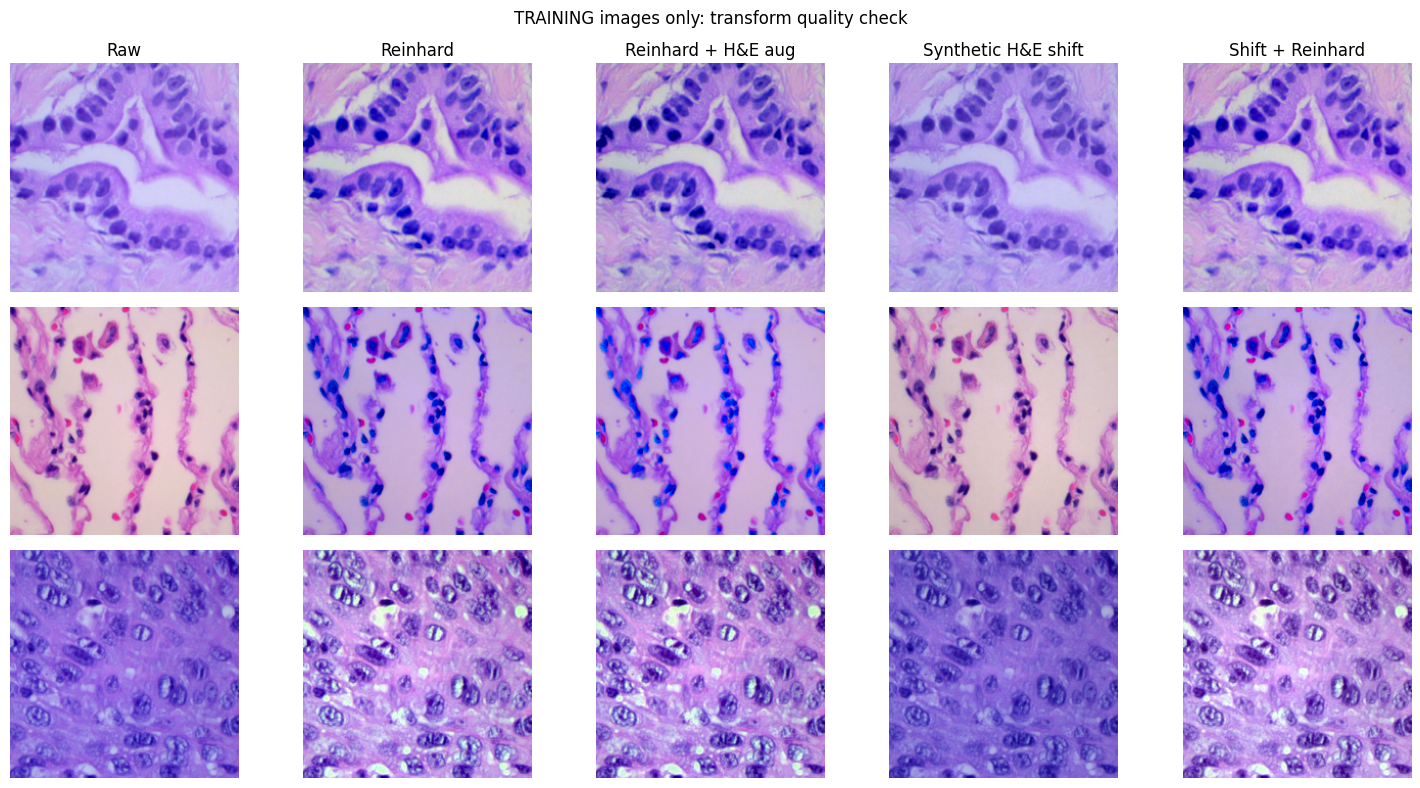

Training-only LAB reference: {'derivation': 'pooled masked LAB moments over deterministic training-only RGB images', 'train_reference_images_per_class': 32, 'train_reference_one_image_per_source_group': True, 'n_training_reference_images': 96, 'n_masked_tissue_pixels': 4816789, 'target_lab_mean': [63.149070739746094, 29.662397384643555, -35.614864349365234], 'target_lab_std': [15.389975547790527, 16.725372314453125, 22.370756149291992], 'tissue_min_mean': 25.0, 'tissue_max_channel': 235.0, 'minimum_tissue_pixels': 256, 'std_scale_bounds': [0.6, 1.8], 'train_reference_index_sha256': '852f11100536651b68ef34ddae8adab652ef22b84e3d3dcb5c7867bd2df28be0'}
Offline augmented training images: 8362 / 10394
Synthetic shifts were fixed before validation evaluation: {'clean': (1.0, 1.0), 'h_up_e_down': (1.25, 0.75), 'h_down_e_up': (0.75, 1.25)}
STOP if train-only preview artifacts appear unacceptable; document the issue before proceeding.


In [8]:
# Fixed LAB reference and deterministic H&E-inspired optical-density perturbation.
import cv2
import matplotlib.pyplot as plt
cv2.setNumThreads(0)

# Canonical H&E optical-density basis (H, E); fixed rather than fitted from validation.
HE_BASIS = np.array([
    [0.650, 0.704, 0.286],
    [0.072, 0.990, 0.105],
], dtype=np.float32)
HE_BASIS /= np.linalg.norm(HE_BASIS, axis=1, keepdims=True)
HE_PINV = np.linalg.pinv(HE_BASIS).astype(np.float32)


def tissue_mask(rgb_0_255):
    rgb = np.asarray(rgb_0_255, dtype=np.float32)
    mean = rgb.mean(axis=2)
    # Ignores near-white and black padding while retaining colored tissue pixels.
    return (mean > TISSUE_MIN_MEAN) & (rgb.min(axis=2) < TISSUE_MAX_CHANNEL)


def to_lab(rgb):
    return cv2.cvtColor(np.clip(rgb / 255.0, 0, 1).astype(np.float32), cv2.COLOR_RGB2LAB)


def he_concentration_shift(image, h_scale=1.0, e_scale=1.0):
    image = np.asarray(image, dtype=np.float32)
    if not (0.70 <= h_scale <= 1.30 and 0.70 <= e_scale <= 1.30):
        raise ValueError('H&E scales exceed the predeclared valid region.')
    if h_scale == 1.0 and e_scale == 1.0:
        return image.copy()  # Exact identity for the clean case.
    mask = tissue_mask(image)
    if mask.sum() < MIN_TISSUE_PIXELS:
        return image.copy()
    rgb = np.maximum(image[mask] / 255.0, 1.0 / 255.0)
    od = -np.log(rgb).astype(np.float32)
    concentrations = np.maximum(od @ HE_PINV, 0.0)
    # Add only the stain-dependent CHANGE to the original OD; preserve residual OD.
    delta = (concentrations * np.array([h_scale - 1, e_scale - 1], dtype=np.float32)) @ HE_BASIS
    shifted_od = np.clip(od + delta, 0.0, 6.0)
    result = image.copy()
    result[mask] = np.clip(np.exp(-shifted_od) * 255.0, 0, 255)
    return result.astype(np.float32, copy=False)


# Exactly 32 images per class, selected only from the original training manifest.
ref_df = pd.concat([
    train_df.loc[train_df['class_name'].eq(name)].sort_values('source_path')
    .drop_duplicates('source_group').sample(
        n=REFERENCE_PER_CLASS, replace=False, random_state=SEED)
    for name in class_names
], ignore_index=True)
if len(ref_df) != REFERENCE_PER_CLASS * len(class_names):
    raise RuntimeError('Wrong number of training reference images.')
if (set(ref_df['split']) != {'train'} or (set(ref_df.source_path) & set(val_df.source_path))
        or ref_df.source_group.nunique() != len(ref_df)):
    raise RuntimeError('Reference images must come exclusively from training.')

lab_sum = np.zeros(3, dtype=np.float64)
lab_sum_sq = np.zeros(3, dtype=np.float64)
ref_tissue_count = 0
ref_low_tissue_images = 0
for image_batch, _ in make_dataset(ref_df, training=False):
    for image in image_batch.numpy():
        m = tissue_mask(image)
        if int(m.sum()) < MIN_TISSUE_PIXELS:
            ref_low_tissue_images += 1
            continue
        lab_pixels = to_lab(image)[m].astype(np.float64)
        ref_tissue_count += len(lab_pixels)
        lab_sum += lab_pixels.sum(axis=0)
        lab_sum_sq += np.square(lab_pixels).sum(axis=0)
if ref_tissue_count < 10000 or ref_low_tissue_images > 0:
    raise ValueError(f'Insufficient usable train-reference tissue pixels; low-tissue images: {ref_low_tissue_images}')
target_mean = (lab_sum / ref_tissue_count).astype(np.float32)
target_var = np.maximum(lab_sum_sq / ref_tissue_count - target_mean.astype(np.float64)**2, 1e-4)
target_std = np.sqrt(target_var).astype(np.float32)
if not np.all(np.isfinite(target_mean)) or not np.all(np.isfinite(target_std)):
    raise FloatingPointError('Invalid fixed training-reference statistics.')
REFERENCE_STATS = {
    'derivation': 'pooled masked LAB moments over deterministic training-only RGB images',
    'train_reference_images_per_class': REFERENCE_PER_CLASS,
    'train_reference_one_image_per_source_group': True,
    'n_training_reference_images': len(ref_df),
    'n_masked_tissue_pixels': int(ref_tissue_count),
    'target_lab_mean': target_mean.astype(float).tolist(),
    'target_lab_std': target_std.astype(float).tolist(),
    'tissue_min_mean': TISSUE_MIN_MEAN,
    'tissue_max_channel': TISSUE_MAX_CHANNEL,
    'minimum_tissue_pixels': MIN_TISSUE_PIXELS,
    'std_scale_bounds': list(REINHARD_SCALE_BOUNDS),
}
REF_INDEX_SHA256 = hashlib.sha256(
    ref_df[['source_path', 'class_id', 'source_group', 'recorded_sha256']].to_csv(
        index=False, lineterminator='\n').encode('utf-8')).hexdigest()
REFERENCE_STATS['train_reference_index_sha256'] = REF_INDEX_SHA256


def reinhard_normalize(image):
    image = np.asarray(image, dtype=np.float32)
    mask = tissue_mask(image)
    if mask.sum() < MIN_TISSUE_PIXELS:
        return image.copy()
    lab = to_lab(image)
    masked = lab[mask]
    current_mean = masked.mean(axis=0)
    current_std = np.maximum(masked.std(axis=0), 1.0)
    ratio = np.clip(target_std / current_std, *REINHARD_SCALE_BOUNDS)
    transformed = (masked - current_mean) * ratio + target_mean
    transformed[:, 0] = np.clip(transformed[:, 0], 0, 100)
    transformed[:, 1:] = np.clip(transformed[:, 1:], -127, 127)
    lab[mask] = transformed
    normalized = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    result = image.copy()
    result[mask] = np.clip(normalized[mask] * 255.0, 0, 255)
    if not np.isfinite(result).all():
        raise FloatingPointError('Stain-normalized image has invalid values.')
    return result.astype(np.float32, copy=False)


# Each training image has at most one offline augmented view. Equal sample counts in H4-N/NA.
rng_aug = np.random.default_rng(SEED)
aug_df = train_df.copy()
aug_choices = rng_aug.random(len(aug_df)) < AUGMENT_PROBABILITY
aug_h = rng_aug.uniform(*AUGMENT_H_RANGE, len(aug_df)).astype(np.float32)
aug_e = rng_aug.uniform(*AUGMENT_E_RANGE, len(aug_df)).astype(np.float32)
aug_df['aug_h'] = np.where(aug_choices, aug_h, 1.0).astype(np.float32)
aug_df['aug_e'] = np.where(aug_choices, aug_e, 1.0).astype(np.float32)
if not np.array_equal(aug_df.source_path.to_numpy(), train_df.source_path.to_numpy()):
    raise ValueError('Augmentation changed the training manifest row order.')


def make_image_dataset(frame, variant='raw', shift='clean'):
    if not set(frame['split']).issubset({'train', 'val'}):
        raise ValueError('H4 refuses held-out test images.')
    if variant not in {'raw', 'norm', 'norm_aug'}:
        raise ValueError('Unknown image variant.')
    if shift not in VALIDATION_SHIFTS:
        raise ValueError('Shift outside predefined protocol.')
    if variant == 'norm_aug' and (set(frame['split']) != {'train'} or shift != 'clean'):
        raise ValueError('Stain-aware training augmentation is training-only.')
    if variant == 'norm_aug' and not {'aug_h','aug_e'}.issubset(frame.columns):
        raise ValueError('Missing fixed offline augmentation scales.')
    h = frame['aug_h'].to_numpy(dtype=np.float32) if variant == 'norm_aug' else np.ones(len(frame), dtype=np.float32)
    e = frame['aug_e'].to_numpy(dtype=np.float32) if variant == 'norm_aug' else np.ones(len(frame), dtype=np.float32)
    ds = tf.data.Dataset.from_tensor_slices((
        frame['local_path'].tolist(), frame['class_id'].to_numpy(dtype=np.int32), h, e))
    options = tf.data.Options()
    options.experimental_deterministic = True
    ds = ds.with_options(options)
    shift_h, shift_e = VALIDATION_SHIFTS[shift]

    def map_row(path, label, h_factor, e_factor):
        image, label = decode_and_resize(path, label)
        if variant == 'raw' and shift == 'clean':
            return image, label
        def numpy_transform(arr, h_value, e_value):
            arr = np.asarray(arr, dtype=np.float32)
            if shift != 'clean':
                arr = he_concentration_shift(arr, shift_h, shift_e)
            if variant in {'norm', 'norm_aug'}:
                arr = reinhard_normalize(arr)
            if variant == 'norm_aug':
                arr = he_concentration_shift(arr, float(h_value), float(e_value))
            return arr.astype(np.float32, copy=False)
        image = tf.numpy_function(numpy_transform, [image, h_factor, e_factor], tf.float32)
        image.set_shape((*IMAGE_SIZE, 3))
        return image, label

    return ds.map(map_row, num_parallel_calls=4, deterministic=True).batch(BATCH_SIZE).prefetch(2)


# Train-only visual quality and invariance checks; no validation pixels are viewed here.
preview_rows = pd.concat([
    train_df.loc[train_df.class_name.eq(name)].head(1) for name in class_names
], ignore_index=True)
preview_raw, _ = next(iter(make_image_dataset(preview_rows, 'raw')))
preview_raw = preview_raw.numpy()
np.testing.assert_array_equal(he_concentration_shift(preview_raw[0]), preview_raw[0])
preview_aug_scales = [(1.16, 0.87), (0.89, 1.13), (1.10, 1.08)]
fig, axes = plt.subplots(len(class_names), 5, figsize=(15, 8))
for i, name in enumerate(class_names):
    original = preview_raw[i]
    norm = reinhard_normalize(original)
    aug = he_concentration_shift(norm, *preview_aug_scales[i])
    stressed = he_concentration_shift(original, *VALIDATION_SHIFTS['h_up_e_down'])
    stress_norm = reinhard_normalize(stressed)
    for j, item in enumerate([original, norm, aug, stressed, stress_norm]):
        if not (item.shape == (*IMAGE_SIZE, 3) and np.isfinite(item).all()
                and 0 <= item.min() <= item.max() <= 255.001):
            raise ValueError('A generated training preview is invalid.')
        axes[i, j].imshow(np.clip(item / 255.0, 0, 1))
        axes[i, j].axis('off')
        if i == 0:
            axes[i, j].set_title(['Raw', 'Reinhard', 'Reinhard + H&E aug',
                                 'Synthetic H&E shift', 'Shift + Reinhard'][j])
    axes[i, 0].set_ylabel(name)
fig.suptitle('TRAINING images only: transform quality check')
fig.tight_layout()
plt.show()
plt.close(fig)
print('Training-only LAB reference:', REFERENCE_STATS)
print('Offline augmented training images:', int(aug_choices.sum()), '/', len(aug_df))
print('Synthetic shifts were fixed before validation evaluation:', VALIDATION_SHIFTS)
print('STOP if train-only preview artifacts appear unacceptable; document the issue before proceeding.')


## 7. Verify H3 reproducibility over the **entire** clean validation partition

H3's exported image-input model was originally checked against cached H3 features on a validation batch. Here verify its **complete 2,273-image validation** predictions against both the saved H3 predictions CSV and the reconstructed two-extractor-plus-saved-head route. This check must pass **before** treating H3 as a robustness control. No checkpoint training or test inference.


In [9]:
# Verify reference feature extraction and H3 full-image inference before H4 training.
for code_name, checkpoint_sha in REFERENCE_CHECKPOINT_SHA256.items():
    if sha256_file(BASELINE_DIRS[code_name] / 'best_model.keras') != checkpoint_sha:
        raise RuntimeError(f'{code_name} checkpoint differs from its H3 reference.')
if H3_CONFIG.get('train_index_sha256') != TRAIN_INDEX_SHA256:
    raise ValueError('H3 train feature ordering differs from the original manifest.')
if H3_CONFIG.get('val_index_sha256') != VAL_INDEX_SHA256:
    raise ValueError('H3 validation feature ordering differs from the original manifest.')

h1_saved = keras.models.load_model(BASELINE_DIRS['H1'] / 'best_model.keras', compile=False)
h2_saved = keras.models.load_model(BASELINE_DIRS['H2'] / 'best_model.keras', compile=False)
h3_head = keras.models.load_model(H3_DIR / 'best_head.keras', compile=False)
h3_image_model = keras.models.load_model(H3_DIR / 'fusion_image_model.keras', compile=False)
if h1_saved.get_layer('mobilenetv2_rescaling').__class__.__name__ != 'Rescaling':
    raise RuntimeError('Missing expected saved H1 native MobileNet preprocessing.')
h2_backbone = h2_saved.get_layer('efficientnetb0')
if not any(isinstance(layer, keras.layers.Rescaling) for layer in h2_backbone.layers):
    raise RuntimeError('Missing saved H2 EfficientNet native image rescaling.')
h1_extractor = keras.Model(
    h1_saved.inputs, h1_saved.get_layer('global_average_pooling').output,
    name='H4_H1_frozen_pooled_1280')
h2_extractor = keras.Model(
    h2_saved.inputs, h2_saved.get_layer('global_average_pooling').output,
    name='H4_H2_frozen_pooled_1280')
h1_extractor.trainable = False
h2_extractor.trainable = False
if (h1_extractor.output_shape[-1], h2_extractor.output_shape[-1]) != (1280, 1280):
    raise ValueError('Pooled feature shape differs from H3 (1280 + 1280).')
if h1_extractor.trainable_weights or h2_extractor.trainable_weights:
    raise RuntimeError('H1/H2 pretrained feature extractors must remain frozen.')
image_input = keras.Input(shape=(*IMAGE_SIZE,3), dtype='float32', name='rgb_0_255')
feature_output = keras.layers.Concatenate(name='h4_pooled_feature_concat')([
    h1_extractor(image_input, training=False),
    h2_extractor(image_input, training=False),
])
feature_model = keras.Model(image_input, feature_output, name='H4_Frozen_H1_H2_Features')
if tuple(feature_model.output_shape[1:]) != (2560,):
    raise ValueError('H4 must extract exactly 2560 concatenated pooled features.')

h3_old_csv = pd.read_csv(H3_DIR / 'validation_predictions.csv', keep_default_na=False)
if len(h3_old_csv) != len(val_df):
    raise ValueError('Historical H3 prediction count differs from validation.')
if not np.array_equal(h3_old_csv.source_path.astype(str), val_df.source_path.astype(str)):
    raise ValueError('Historical H3 predictions do not match validation order.')
if not np.array_equal(h3_old_csv.true_id.to_numpy(dtype=np.int32),
                      val_df.class_id.to_numpy(dtype=np.int32)):
    raise ValueError('Historical H3 true labels differ.')
score_cols = ['score_' + name for name in class_names]
if not all(col in h3_old_csv for col in score_cols):
    raise ValueError('Saved H3 probabilities are incomplete.')
original_h3_scores = h3_old_csv[score_cols].to_numpy(dtype=np.float32)
print('Checking exported H3 image model on all 2,273 CLEAN validation images...')
h3_full_clean_scores = h3_image_model.predict(make_image_dataset(val_df, 'raw'), verbose=1)
np.testing.assert_allclose(h3_full_clean_scores, original_h3_scores, atol=4e-4, rtol=4e-4)
print('Checking separately reassembled H1+H2 pooled features on all validation images...')
h3_clean_features = feature_model.predict(make_image_dataset(val_df, 'raw'), verbose=1)
if h3_clean_features.shape != (len(val_df), 2560):
    raise ValueError('Full clean validation feature-matrix shape incorrect.')
h3_reconstructed_scores = h3_head.predict(h3_clean_features, batch_size=BATCH_SIZE, verbose=0)
np.testing.assert_allclose(h3_reconstructed_scores, original_h3_scores, atol=4e-4, rtol=4e-4)
np.testing.assert_allclose(h3_full_clean_scores, h3_reconstructed_scores, atol=4e-4, rtol=4e-4)
if not np.array_equal(h3_reconstructed_scores.argmax(axis=1),
                      h3_old_csv.predicted_id.to_numpy(dtype=np.int32)):
    raise ValueError('H3 reconstructed predictions disagree with saved H3 predictions.')
print('H3 full validation reference consistency passed: 2,273 / 2,273 rows.')
print('Historical H3 validation accuracy:', H3_METRICS['accuracy'])
print('Held-out test set is still untouched.')


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 6 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Checking exported H3 image model on all 2,273 CLEAN validation images...
143/143 ━━━━━━━━━━━━━━━━━━━━ 25s 139ms/step
Checking separately reassembled H1+H2 pooled features on all validation images...
143/143 ━━━━━━━━━━━━━━━━━━━━ 23s 136ms/step
H3 full validation reference consistency passed: 2,273 / 2,273 rows.
Historical H3 validation accuracy: 0.9802023757149142
Held-out test set is still untouched.


## 8. Extract **new** normalized / augmented feature caches

The existing H3 unmodified feature cache **cannot** represent stained inputs. The cache created here is fingerprinted to the original manifest, the saved H1/H2 checkpoints, the training-only color reference, transform parameters, manifest order and software. It contains **H4-N and H4-NA training features** and the **predefined clean/shifted validation features** for comparisons. H4-N and H4-NA both use exactly 10,394 training rows. Only the new H4 cache directory is written.

This is the most GPU- and I/O-intensive step. For a brand-new cache, the cell asks `CACHE H4` before it begins. Do not repeatedly extract or overwrite an existing successful cache.


In [10]:
# Create/reuse a persistent H4-only cache with full SHA-256 provenance.
import shutil
import time

H4_PROTOCOL = {
    'transform_version': 'h4_reinhard_residual_he_v1',
    'input_shape': [224,224,3],
    'resize': 'tf.image.resize_with_pad, bilinear, antialias=True',
    'input_range': [0,255], 'output_range': [0,255],
    'reinhard': REFERENCE_STATS,
    'he_basis_rows': HE_BASIS.astype(float).tolist(),
    'he_shift_math': 'OD_new = OD_old + max(OD_old @ pinv(HE_basis),0) * (factors-1) @ HE_basis',
    'train_aug_probability': AUGMENT_PROBABILITY,
    'train_aug_h_range': list(AUGMENT_H_RANGE),
    'train_aug_e_range': list(AUGMENT_E_RANGE),
    'train_aug_order': 'Reinhard normalization THEN H&E-inspired perturbation',
    'train_aug_views_per_image': 1,
    'val_stress_order': 'synthetic H&E shift THEN Reinhard normalization (H4 only)',
    'validation_stress_shifts': {k: list(v) for k, v in VALIDATION_SHIFTS.items()},
    'opencv_version': cv2.__version__,
}
aug_index_data = aug_df[['source_path', 'aug_h', 'aug_e']].to_csv(
    index=False, lineterminator='\n').encode('utf-8')
AUG_INDEX_SHA256 = hashlib.sha256(aug_index_data).hexdigest()
CACHE_INPUTS = {
    'manifest_sha256': SOURCE_SHA256['manifest'], 'archive_sha256': ARCHIVE_SHA256,
    'H1_checkpoint_sha256': REFERENCE_CHECKPOINT_SHA256['H1'],
    'H2_checkpoint_sha256': REFERENCE_CHECKPOINT_SHA256['H2'],
    'H3_head_sha256': H3_HEAD_SHA256,
    'train_index_sha256': TRAIN_INDEX_SHA256, 'val_index_sha256': VAL_INDEX_SHA256,
    'aug_draws_sha256': AUG_INDEX_SHA256,
    'protocol': H4_PROTOCOL,
    'tensorflow_version': tf.__version__, 'keras_version': keras.__version__,
}
CACHE_KEY = hashlib.sha256(json.dumps(CACHE_INPUTS, sort_keys=True).encode()).hexdigest()
H4_CACHE_DIR = CACHE_ROOT / ('H4_stain_' + CACHE_KEY[:16])
H4_CACHE_METADATA = H4_CACHE_DIR / 'cache_metadata.json'
CACHE_VARIANTS = {
    'train_norm': (train_df, 'norm', 'clean'),
    'train_norm_aug': (aug_df, 'norm_aug', 'clean'),
    'val_norm_clean': (val_df, 'norm', 'clean'),
    'val_raw_h_up_e_down': (val_df, 'raw', 'h_up_e_down'),
    'val_norm_h_up_e_down': (val_df, 'norm', 'h_up_e_down'),
    'val_raw_h_down_e_up': (val_df, 'raw', 'h_down_e_up'),
    'val_norm_h_down_e_up': (val_df, 'norm', 'h_down_e_up'),
}
CACHE_FILES = [key + '.npy' for key in CACHE_VARIANTS]
print('Unique H4 stain-feature cache:', H4_CACHE_DIR)


def verify_and_load_cache(folder):
    meta = read_json(folder / 'cache_metadata.json')
    if meta.get('cache_key') != CACHE_KEY or meta.get('inputs') != CACHE_INPUTS:
        raise ValueError('H4 cache key or protocol changed. Never accept a mismatched cache.')
    loaded = {}
    for key, (frame, _, _) in CACHE_VARIANTS.items():
        path = folder / (key + '.npy')
        if not path.is_file() or sha256_file(path) != meta['files_sha256'].get(path.name):
            raise ValueError('Missing/corrupt H4 feature cache: ' + str(path))
        feat = np.load(path, allow_pickle=False)
        if feat.shape != (len(frame), 2560) or feat.dtype != np.float32:
            raise ValueError('Cached feature shape/dtype mismatch: ' + key)
        if not np.isfinite(feat).all():
            raise FloatingPointError('Cached non-finite H4 features: ' + key)
        loaded[key] = feat
    for name, frame in [('train_index.csv', train_df), ('val_index.csv', val_df)]:
        path = folder / name
        if not path.is_file() or sha256_file(path) != meta['files_sha256'].get(name):
            raise ValueError('Missing/corrupt H4 manifest-order index: ' + name)
        cols = ['source_path','class_id','source_group','recorded_sha256']
        actual = pd.read_csv(path, dtype=str, keep_default_na=False)
        if not actual.equals(frame[cols].astype(str).reset_index(drop=True)):
            raise ValueError('H4 feature cache index and original manifest disagree.')
    for name in ['reference_stats.json', 'augmentation_factors.csv']:
        if sha256_file(folder / name) != meta['files_sha256'].get(name):
            raise ValueError('Cached training reference/augmentation metadata changed.')
    return loaded, meta


if H4_CACHE_DIR.exists():
    H4_FEATURES, H4_CACHE_INFO = verify_and_load_cache(H4_CACHE_DIR)
    print('Verified and reused original H4 stain cache.')
else:
    if MODE == 'evaluate_saved':
        raise FileNotFoundError('The original H4 feature cache is required for evaluate_saved mode.')
    if input('Generate H4 train/validation stained features? Type CACHE H4: ').strip() != 'CACHE H4':
        raise RuntimeError('Feature cache generation cancelled before writing.')
    if RUN_DIR.exists():
        raise FileExistsError('H4 results folder exists; stop and inspect before extracting a new cache.')
    CACHE_ROOT.mkdir(parents=True, exist_ok=True)
    building = H4_CACHE_DIR.with_name(H4_CACHE_DIR.name + '.building')
    if building.exists():
        raise FileExistsError('Previous incomplete cache build detected. Inspect it first: ' + str(building))
    building.mkdir(parents=True, exist_ok=False)
    files_sha = {}
    started = time.perf_counter()
    for key, (frame, variant, shift) in CACHE_VARIANTS.items():
        print(f'Extracting {key}: n={len(frame)}, preprocessing={variant}, shift={shift}')
        feats = feature_model.predict(make_image_dataset(frame, variant, shift), verbose=1)
        feats = np.asarray(feats, dtype=np.float32)
        if feats.shape != (len(frame),2560) or not np.isfinite(feats).all():
            raise ValueError('New H4 feature matrix failed verification: ' + key)
        path = building / (key + '.npy')
        with path.open('wb') as writer:
            np.save(writer, feats, allow_pickle=False)
        files_sha[path.name] = sha256_file(path)
        del feats
    cols = ['source_path','class_id','source_group','recorded_sha256']
    for filename, frame in [('train_index.csv', train_df), ('val_index.csv', val_df)]:
        path = building / filename
        frame[cols].to_csv(path, index=False)
        files_sha[filename] = sha256_file(path)
    (building / 'reference_stats.json').write_text(
        json.dumps(REFERENCE_STATS, indent=2, allow_nan=False), encoding='utf-8')
    (building / 'augmentation_factors.csv').write_bytes(aug_index_data)
    for filename in ['reference_stats.json', 'augmentation_factors.csv']:
        files_sha[filename] = sha256_file(building / filename)
    H4_CACHE_INFO = {
        'cache_key': CACHE_KEY, 'inputs': CACHE_INPUTS,
        'features_cached': list(CACHE_VARIANTS),
        'train_rows_per_new_condition': len(train_df),
        'validation_rows_per_condition_and_shift': len(val_df),
        'test_pixels_read': False,
        'elapsed_seconds': round(time.perf_counter() - started, 2),
        'files_sha256': files_sha,
    }
    (building / 'cache_metadata.json').write_text(
        json.dumps(H4_CACHE_INFO, indent=2, allow_nan=False), encoding='utf-8')
    building.replace(H4_CACHE_DIR)
    H4_FEATURES, H4_CACHE_INFO = verify_and_load_cache(H4_CACHE_DIR)
    print('New H4-only stain cache saved and re-verified:', H4_CACHE_DIR)

train_y = train_df.class_id.to_numpy(dtype=np.int32)
val_y = val_df.class_id.to_numpy(dtype=np.int32)
if len(train_y) != EXPECTED_IMAGES['train'] or len(val_y) != EXPECTED_IMAGES['val']:
    raise ValueError('H4 train/validation labels do not match fixed split counts.')
print('H4 cache conditions and shapes:')
for key, feat in H4_FEATURES.items():
    print(' ', key, feat.shape)
print('All H4 input features come from the saved frozen H1+H2 pooled representations.')
print('Held-out test images were not accessed.')


Unique H4 stain-feature cache: /content/drive/MyDrive/ICTIU_Final_Projects/lung/feature_cache/H4_stain_a28fa20606419f6c
Generate H4 train/validation stained features? Type CACHE H4: CACHE H4
Extracting train_norm: n=10394, preprocessing=norm, shift=clean
650/650 ━━━━━━━━━━━━━━━━━━━━ 301s 463ms/step
Extracting train_norm_aug: n=10394, preprocessing=norm_aug, shift=clean
650/650 ━━━━━━━━━━━━━━━━━━━━ 357s 549ms/step
Extracting val_norm_clean: n=2273, preprocessing=norm, shift=clean
143/143 ━━━━━━━━━━━━━━━━━━━━ 67s 465ms/step
Extracting val_raw_h_up_e_down: n=2273, preprocessing=raw, shift=h_up_e_down
143/143 ━━━━━━━━━━━━━━━━━━━━ 48s 336ms/step
Extracting val_norm_h_up_e_down: n=2273, preprocessing=norm, shift=h_up_e_down
143/143 ━━━━━━━━━━━━━━━━━━━━ 83s 581ms/step
Extracting val_raw_h_down_e_up: n=2273, preprocessing=raw, shift=h_down_e_up
143/143 ━━━━━━━━━━━━━━━━━━━━ 48s 333ms/step
Extracting val_norm_h_down_e_up: n=2273, preprocessing=norm, shift=h_down_e_up
143/143 ━━━━━━━━━━━━━━━━━━━━

## 9. Freeze H4 run configuration; check the new classification head

Construct the **same** 7,683-parameter H3-style fusion head (dropout 0.2, three-class softmax), with frozen H1/H2 feature extraction and 2,560 input features. Validate a **disposable** gradient and save/load smoke test; discard it. Lock seed 42, class weights, batch size 16, Adam 0.001, maximum six epochs, early stopping patience two, and minimum validation loss checkpoint selection.

Neither completed experiment is trained in this section.


In [11]:
# Training-only class weights, comparable head architecture, and frozen configuration.
from collections import Counter
class_counts = train_df.class_id.value_counts().reindex(range(3))
class_weights = {int(k): float(len(train_df) / (3*count)) for k, count in class_counts.items()}
EXPECTED_HEAD_PARAMS = (2560 + 1)*len(class_names)


def build_h4_head():
    x_in = keras.Input(shape=(2560,), dtype='float32', name='fused_features')
    x = keras.layers.Dropout(DROPOUT, seed=SEED, name='fusion_dropout')(x_in)
    prob = keras.layers.Dense(3, activation='softmax', name='fusion_class_scores')(x)
    model = keras.Model(x_in, prob, name='H4_Fusion_Classification_Head')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')])
    return model


def save_json(path, value):
    path = Path(path)
    temp = path.with_name(path.name + '.tmp')
    temp.write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')
    temp.replace(path)


def make_feature_dataset(features, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((features, labels))
    if training:
        ds = ds.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(2)

CONFIG = {
    'notebook': 'H4_Lung_Stain_Normalization_Augmentation_Robustness.ipynb',
    'notebook_revision': '2026-10-19-h4-v1',
    'run_name': RUN_NAME,
    'experiment': 'Fixed-reference Reinhard plus offline H&E-inspired train-only augmentation',
    'comparison_conditions': ['H3_original',H4_N,H4_NA],
    'class_to_id': class_to_id, 'class_names': class_names,
    'source_sha256': SOURCE_SHA256, 'archive_sha256': ARCHIVE_SHA256,
    'source_group_counts': EXPECTED_GROUPS, 'image_counts': EXPECTED_IMAGES,
    'grouping_unit': 'reconstructed source-image group, NOT patient ID',
    'H1_H2_checkpoint_sha256': REFERENCE_CHECKPOINT_SHA256,
    'H3_head_sha256': H3_HEAD_SHA256,
    'H3_image_model_sha256': H3_IMAGE_SHA256,
    'H3_validation_metrics_sha256': sha256_file(H3_DIR / 'validation_metrics.json'),
    'frozen_feature_vector': '1280 MobileNetV2 GAP + 1280 EfficientNetB0 GAP',
    'train_index_sha256': TRAIN_INDEX_SHA256, 'val_index_sha256': VAL_INDEX_SHA256,
    'protocol': H4_PROTOCOL,
    'feature_cache_key': CACHE_KEY,
    'feature_cache_dir': str(H4_CACHE_DIR),
    'feature_cache_metadata_sha256': sha256_file(H4_CACHE_METADATA),
    'augmentation_factors_sha256': AUG_INDEX_SHA256,
    'same_train_rows_per_condition': len(train_df),
    'training_seed': SEED, 'head_trainable_parameters': EXPECTED_HEAD_PARAMS,
    'optimizer': 'Adam', 'learning_rate': LEARNING_RATE,
    'dropout': DROPOUT, 'batch_size': BATCH_SIZE,
    'loss': 'SparseCategoricalCrossentropy',
    'class_weights': {str(k): v for k,v in class_weights.items()},
    'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
    'checkpoint_monitor': 'val_loss', 'checkpoint_mode': 'min',
    'validation_only': True, 'held_out_test_evaluated': False,
    'features_precomputed_offline': True, 'backbones_frozen': True,
    'train_aug_single_fixed_view_not_epochwise': True,
}
CONFIG_SHA256 = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode('utf-8')).hexdigest()
if MODE == 'evaluate_saved' and read_json(RUN_DIR / 'configuration.json') != CONFIG:
    raise ValueError('Saved H4 configuration differs; refuse silent reproduction changes.')
keras.utils.set_random_seed(SEED)
smoke = build_h4_head()
param_count = int(sum(np.prod(w.shape) for w in smoke.trainable_weights))
if param_count != EXPECTED_HEAD_PARAMS:
    raise ValueError('Fusion head must have exactly 7,683 trainable parameters.')
smoke_result = smoke.train_on_batch(H4_FEATURES['train_norm'][:16], train_y[:16], return_dict=True)
if not all(np.isfinite(float(v)) for v in smoke_result.values()):
    raise FloatingPointError('Disposable head gradients failed.')
smoke_probs = smoke.predict(H4_FEATURES['val_norm_clean'][:4], verbose=0)
np.testing.assert_allclose(smoke_probs.sum(axis=1), 1.0, atol=2e-5)
SMOKE_PATH = LOCAL_ROOT / 'h4_disposable_smoke.keras'
smoke.save(SMOKE_PATH)
smoke_copy = keras.models.load_model(SMOKE_PATH, compile=False)
np.testing.assert_allclose(smoke_copy.predict(H4_FEATURES['val_norm_clean'][:4], verbose=0),
                           smoke_probs, rtol=1e-5, atol=1e-5)
SMOKE_PATH.unlink(missing_ok=True)
del smoke, smoke_copy
SMOKE_TEST_PASSED = True
print('H4 training configuration fingerprint:', CONFIG_SHA256)
print('Trainable head parameters:', param_count)
print('Class weights:', class_weights)
print('Disposable gradient and save/load smoke test passed; no H4 research model trained yet.')


H4 training configuration fingerprint: e7ef410aefa49bf05e3d858c5f9a4102eecb0fdda031d8df40b12bcec48fbfed
Trainable head parameters: 7683
Class weights: {0: 0.9973133755517175, 1: 1.0048337200309359, 2: 0.9978878648233487}
Disposable gradient and save/load smoke test passed; no H4 research model trained yet.


## 10. Fit H4-N on normalized training features (explicit confirmation)

This cell starts the **first** H4 condition. It creates a new H4 result directory, saves all configuration and source fingerprints, and fits the same H3-style head on **10,394 train-only Reinhard features**. Validation is used for early stopping and choosing minimum-`val_loss` checkpoint. It does not alter H1/H2/H3 or evaluate test data.

Type `TRAIN H4 N` only after confirming all preceding checks passed. If an interrupted result folder remains, **stop and inspect it**; do not delete or silently overwrite it.


In [12]:
# New H4-N training, protected checkpoint and restart provenance.
from datetime import datetime, timezone
import time


def fit_h4_condition(condition, features, title):
    if features.shape != (len(train_df), 2560):
        raise ValueError('Only the complete fixed training-feature matrix may be fitted.')
    cond_dir = RUN_DIR / condition
    if cond_dir.exists():
        raise FileExistsError('A result already exists for this condition: ' + str(cond_dir))
    status = read_json(RUN_DIR / 'training_status.json')
    if status.get('configuration_sha256') != CONFIG_SHA256:
        raise RuntimeError('H4 run configuration changed since run initialization.')
    if condition in status.get('conditions', {}):
        raise FileExistsError('Existing H4 condition must not be trained again.')
    cond_dir.mkdir(parents=True, exist_ok=False)
    status['conditions'][condition] = {
        'state': 'starting', 'started_utc': datetime.now(timezone.utc).isoformat(),
        'epochs_completed': 0,
    }
    save_json(RUN_DIR / 'training_status.json', status)

    class SaveEpochStatus(keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            if not all(np.isfinite(float(v)) for v in logs.values()):
                raise FloatingPointError('H4 training produced a non-finite epoch metric.')
            status['conditions'][condition].update({
                'state': 'training', 'epochs_completed': epoch+1,
                'last_epoch_metrics': {key: float(value) for key,value in logs.items()},
            })
            save_json(RUN_DIR / 'training_status.json', status)

    started = time.perf_counter()
    try:
        keras.utils.set_random_seed(SEED)  # Same initial head weights for both H4 variants.
        head = build_h4_head()
        callbacks = [
            keras.callbacks.TerminateOnNaN(),
            keras.callbacks.ModelCheckpoint(str(cond_dir/'best_head.keras'),
                monitor='val_loss', mode='min', save_best_only=True, verbose=1),
            keras.callbacks.CSVLogger(str(cond_dir/'training_history.csv')),
            keras.callbacks.EarlyStopping(monitor='val_loss', mode='min',
                patience=PATIENCE, restore_best_weights=True, verbose=1),
            SaveEpochStatus(),
        ]
        history = head.fit(
            make_feature_dataset(features, train_y, training=True),
            validation_data=make_feature_dataset(H4_FEATURES['val_norm_clean'], val_y),
            class_weight=class_weights, epochs=MAX_EPOCHS,
            callbacks=callbacks, verbose=1)
        if not (cond_dir/'best_head.keras').is_file():
            raise FileNotFoundError('No best H4 condition checkpoint was saved.')
        epoch_table = pd.read_csv(cond_dir/'training_history.csv')
        epoch_min = int(epoch_table['val_loss'].idxmin())
        best_epoch = int(epoch_table.iloc[epoch_min]['epoch']) + 1
        status['conditions'][condition].update({
            'state': 'trained', 'epochs_completed': len(history.history['loss']),
            'best_epoch': best_epoch,
            'best_val_loss': float(epoch_table.iloc[epoch_min]['val_loss']),
            'best_checkpoint_sha256': sha256_file(cond_dir/'best_head.keras'),
            'elapsed_seconds': round(time.perf_counter()-started, 2),
            'finished_utc': datetime.now(timezone.utc).isoformat(),
            'held_out_test_evaluated': False,
        })
        save_json(RUN_DIR / 'training_status.json', status)
        print(f'{title} trained; minimum-validation-loss checkpoint epoch: {best_epoch}')
        del head
    except BaseException as err:
        status['conditions'][condition]['state'] = 'interrupted_or_failed'
        status['conditions'][condition]['error'] = repr(err)
        save_json(RUN_DIR / 'training_status.json', status)
        raise


if MODE == 'evaluate_saved':
    if not (RUN_DIR/H4_N/'best_head.keras').is_file():
        raise FileNotFoundError('H4-N saved head is absent.')
    print('H4-N training skipped in evaluate_saved mode.')
else:
    if not globals().get('SMOKE_TEST_PASSED', False):
        raise RuntimeError('Disposable H4 head checks were not completed.')
    if RUN_DIR.exists():
        raise FileExistsError('New run directory is not empty; refusing overwrite.')
    if sha256_file(H4_CACHE_METADATA) != CONFIG['feature_cache_metadata_sha256']:
        raise RuntimeError('H4 feature cache changed after configuration was frozen.')
    if input('Start new Reinhard-only head training? Type TRAIN H4 N: ').strip() != 'TRAIN H4 N':
        raise RuntimeError('H4-N training not authorized. No run directory created.')
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    (RUN_DIR/'provenance').mkdir(exist_ok=False)
    save_json(RUN_DIR/'configuration.json', CONFIG)
    save_json(RUN_DIR/'environment.json', ENVIRONMENT)
    save_json(RUN_DIR/'reference_stats.json', REFERENCE_STATS)
    save_json(RUN_DIR/'data_checks.json', DATA_CHECKS)
    shutil.copy2(H4_CACHE_METADATA, RUN_DIR/'cache_metadata.json')
    for role in ('manifest','mapping','groups','audit'):
        shutil.copy2(SOURCE_FILES[role], RUN_DIR/'provenance'/SOURCE_FILES[role].name)
    ref_df[['source_path','class_id','source_group','recorded_sha256']].to_csv(
        RUN_DIR/'reference_training_images.csv', index=False)
    shutil.copy2(H4_CACHE_DIR/'augmentation_factors.csv', RUN_DIR/'augmentation_factors.csv')
    save_json(RUN_DIR/'training_status.json', {
        'state': 'partially_trained',
        'configuration_sha256': CONFIG_SHA256,
        'conditions': {}, 'held_out_test_evaluated': False,
        'started_utc': datetime.now(timezone.utc).isoformat(),
    })
    fit_h4_condition(H4_N, H4_FEATURES['train_norm'], 'H4-N (Reinhard only)')
print('H4-N stage complete. No held-out test evaluation.')


Start new Reinhard-only head training? Type TRAIN H4 N: TRAIN H4 N
Epoch 1/6
645/650 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9038 - loss: 0.2192
Epoch 1: val_loss improved from None to 0.08753, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42/H4_N_reinhard/best_head.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42/H4_N_reinhard/best_head.keras
650/650 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9475 - loss: 0.1269 - val_accuracy: 0.9644 - val_loss: 0.0875
Epoch 2/6
640/650 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9783 - loss: 0.0554
Epoch 2: val_loss did not improve from 0.08753
650/650 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9796 - loss: 0.0518 - val_accuracy: 0.9644 - val_loss: 0.0893
Epoch 3/6
648/650 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9873 - loss: 0.0381
Epoch 3: val_loss improved from 0.08753 to 0.0865

## 11. Fit H4-NA using fixed **train-only** H&E-augmented features

Use the same frozen source backbones, 10,394 **original training rows**, hyperparameters, class weights and same normalized validation features as H4-N. H4-NA differs only by its **single deterministic augmented training view** per original image (about 80% altered). No validation augmentation is applied during checkpoint selection. No reference checkpoint or data split is changed.

Type `TRAIN H4 NA` for the second head. This cell does **not** retrain H4-N.


In [13]:
# Second H4 condition: same head protocol, fixed offline train-only H&E augmentation.
if MODE == 'evaluate_saved':
    if not (RUN_DIR/H4_NA/'best_head.keras').is_file():
        raise FileNotFoundError('H4-NA saved checkpoint is absent.')
    print('H4-NA training skipped in evaluate_saved mode.')
else:
    existing_status = read_json(RUN_DIR/'training_status.json')
    if existing_status.get('conditions',{}).get(H4_N,{}).get('state') != 'trained':
        raise RuntimeError('H4-N must complete before starting H4-NA.')
    if (RUN_DIR/H4_NA).exists():
        raise FileExistsError('H4-NA condition directory exists; refuse to overwrite.')
    if sha256_file(H4_CACHE_METADATA) != CONFIG['feature_cache_metadata_sha256']:
        raise RuntimeError('Stain-feature cache changed after H4-N training.')
    if input('Start H&E-augmented training view? Type TRAIN H4 NA: ').strip() != 'TRAIN H4 NA':
        raise RuntimeError('H4-NA training not authorized; H4-N is preserved.')
    fit_h4_condition(H4_NA, H4_FEATURES['train_norm_aug'],
                     'H4-NA (Reinhard plus fixed H&E training augmentation)')
    final_status = read_json(RUN_DIR/'training_status.json')
    if not all(final_status['conditions'][k]['state']=='trained' for k in [H4_N,H4_NA]):
        raise RuntimeError('Both H4 heads must have a completed training status.')
    final_status['state'] = 'trained_not_validated'
    save_json(RUN_DIR/'training_status.json', final_status)
print('Both H4 heads are trained. Validation robustness evaluation remains next.')


Start H&E-augmented training view? Type TRAIN H4 NA: TRAIN H4 NA
Epoch 1/6
640/650 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9053 - loss: 0.2216
Epoch 1: val_loss improved from None to 0.08822, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42/H4_NA_reinhard_he_aug/best_head.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42/H4_NA_reinhard_he_aug/best_head.keras
650/650 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9473 - loss: 0.1295 - val_accuracy: 0.9626 - val_loss: 0.0882
Epoch 2/6
643/650 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9786 - loss: 0.0554
Epoch 2: val_loss improved from 0.08822 to 0.08527, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42/H4_NA_reinhard_he_aug/best_head.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/

## 12. Clean and synthetic H&E-shifted **validation-only** evaluation

Compare all three **already-trained** conditions on exactly the same original 2,273 validation images, with three views: `clean`, `h_up_e_down`, and `h_down_e_up`. The predefined synthetic shift is applied to each RGB image before H4 stain normalization; H3 sees the raw shifted RGB. H4-N and H4-NA receive exactly the same normalized validation feature matrix for each shift. Their H&E augmentation is not applied at validation inference.

Save all class-wise precision, recall and F1, confusion matrices, prediction probabilities, clean macro-F1, both shifted macro-F1 values, and the *drop from clean* under each synthetic shift. Prefer **macro-F1** and per-class errors over accuracy alone. Results are **validation-only** and no statement of external clinical robustness is justified.


In [14]:
# Comprehensive validation-only comparison. No test records are in any dataset.
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, log_loss)

saved_status = read_json(RUN_DIR/'training_status.json')
for k in [H4_N, H4_NA]:
    if saved_status.get('conditions',{}).get(k,{}).get('state') != 'trained':
        raise RuntimeError('Both H4 heads must finish training before validation analysis.')
    if sha256_file(RUN_DIR/k/'best_head.keras') != saved_status['conditions'][k]['best_checkpoint_sha256']:
        raise RuntimeError('Saved H4 checkpoint checksum changed: ' + k)
new_heads = {k: keras.models.load_model(RUN_DIR/k/'best_head.keras', compile=False)
             for k in [H4_N,H4_NA]}
for k, model in new_heads.items():
    if model.input_shape != (None,2560) or model.output_shape != (None,3):
        raise ValueError(f'Unexpected shape in saved {k} classifier.')

score_rows = []
validation_details = {}
all_scores = {}
for condition in ['H3_original',H4_N,H4_NA]:
    for shift_name in VALIDATION_SHIFTS:
        if condition == 'H3_original':
            if shift_name == 'clean':
                proba = h3_full_clean_scores
            else:
                proba = h3_head.predict(
                    H4_FEATURES['val_raw_' + shift_name], batch_size=BATCH_SIZE, verbose=0)
        else:
            proba = new_heads[condition].predict(
                H4_FEATURES['val_norm_' + shift_name], batch_size=BATCH_SIZE, verbose=0)
        proba = np.asarray(proba, dtype=np.float32)
        if proba.shape != (len(val_df),3) or not np.isfinite(proba).all():
            raise ValueError('Invalid H4 validation predictions.')
        np.testing.assert_allclose(proba.sum(axis=1), 1, atol=2e-4)
        predicted = proba.argmax(axis=1).astype(np.int32)
        f1_macro = float(f1_score(val_y, predicted, average='macro',
                                   labels=[0,1,2], zero_division=0))
        correct = int((predicted == val_y).sum())
        cm = confusion_matrix(val_y, predicted, labels=[0,1,2])
        classification = classification_report(
            val_y, predicted, labels=[0,1,2], target_names=class_names,
            output_dict=True, zero_division=0)
        key = condition + '__' + shift_name
        validation_details[key] = {
            'condition': condition, 'validation_shift': shift_name,
            'n_validation_images': len(val_y),
            'validation_accuracy': float(accuracy_score(val_y,predicted)),
            'validation_macro_f1': f1_macro,
            'validation_log_loss': float(log_loss(val_y, proba, labels=[0,1,2])),
            'correct': correct, 'errors': len(val_y)-correct,
            'confusion_matrix': cm.tolist(), 'classification_report': classification,
            'held_out_test_evaluated': False,
        }
        score_rows.append({
            'condition':condition, 'shift':shift_name,
            'n_validation_images':len(val_y), 'correct':correct,
            'validation_accuracy': validation_details[key]['validation_accuracy'],
            'validation_macro_f1': f1_macro,
            'validation_log_loss': validation_details[key]['validation_log_loss'],
        })
        all_scores[key] = proba

VALIDATION_TABLE = pd.DataFrame(score_rows)
for condition in VALIDATION_TABLE['condition'].unique():
    mask = VALIDATION_TABLE['condition'].eq(condition)
    clean_row = VALIDATION_TABLE.loc[mask & VALIDATION_TABLE['shift'].eq('clean')].iloc[0]
    VALIDATION_TABLE.loc[mask, 'clean_macro_f1'] = clean_row.validation_macro_f1
    VALIDATION_TABLE.loc[mask, 'macro_f1_drop_from_clean'] = (
        clean_row.validation_macro_f1 - VALIDATION_TABLE.loc[mask,'validation_macro_f1'])
if abs(float(VALIDATION_TABLE.loc[
        VALIDATION_TABLE.condition.eq('H3_original') & VALIDATION_TABLE['shift'].eq('clean'),
        'validation_accuracy'].iloc[0]) - float(H3_METRICS['accuracy'])) > 1e-7:
    raise RuntimeError('H3 baseline validation metric changed; comparison must stop.')

ROBUSTNESS_TABLE = VALIDATION_TABLE.pivot(
    index='condition', columns='shift', values='validation_macro_f1')
ROBUSTNESS_TABLE['shift_mean_macro_f1'] = ROBUSTNESS_TABLE[
    ['h_up_e_down', 'h_down_e_up']].mean(axis=1)
ROBUSTNESS_TABLE['worst_shift_macro_f1'] = ROBUSTNESS_TABLE[
    ['h_up_e_down', 'h_down_e_up']].min(axis=1)
ROBUSTNESS_TABLE['mean_drop_from_clean'] = (
    ROBUSTNESS_TABLE['clean'] - ROBUSTNESS_TABLE['shift_mean_macro_f1'])
print('All reported figures below use the VALIDATION split only.')
display(VALIDATION_TABLE.round(5))
print('Synthetic stain-robustness descriptive comparison (validation only):')
display(ROBUSTNESS_TABLE.round(5))

# Store the complete, correctly labeled validation-only evidence for a new run.
if MODE == 'train_new':
    prediction_folder = RUN_DIR/'validation_predictions_by_condition'
    if prediction_folder.exists():
        raise FileExistsError('Validation output folder exists; stop rather than overwrite.')
    prediction_folder.mkdir(parents=False, exist_ok=False)
    for key, proba in all_scores.items():
        condition, shift_name = key.split('__')
        guesses = proba.argmax(axis=1).astype(np.int32)
        rows = val_df[['source_path','source_group','class_name','class_id']].copy()
        rows.columns = ['source_path','source_group','true_class','true_id']
        rows['predicted_id'] = guesses
        rows['predicted_class'] = [class_names[i] for i in guesses]
        for i,name in enumerate(class_names):
            rows['score_' + name] = proba[:,i]
        rows.to_csv(prediction_folder/(key+'.csv'),index=False)
    VALIDATION_TABLE.to_csv(RUN_DIR/'validation_condition_metrics.csv',index=False)
    ROBUSTNESS_TABLE.to_csv(RUN_DIR/'validation_robustness_summary.csv')
    save_json(RUN_DIR/'validation_details.json', validation_details)
    saved_status['state'] = 'validated_not_exported'
    saved_status['validation_conditions_completed'] = len(VALIDATION_TABLE)
    saved_status['held_out_test_evaluated'] = False
    save_json(RUN_DIR/'training_status.json', saved_status)
print('All three conditions evaluated on clean + two fixed synthetic VALIDATION shifts.')
print('Held-out test set remains untouched. No automatic model selection was made.')


All reported figures below use the VALIDATION split only.


,condition,shift,n_validation_images,correct,validation_accuracy,validation_macro_f1,validation_log_loss,clean_macro_f1,macro_f1_drop_from_clean
0,H3_original,clean,2273,2228,0.98020,0.98014,0.04874,0.98014,0.00000
1,H3_original,h_up_e_down,2273,2219,0.97624,0.97615,0.05681,0.98014,0.00399
2,H3_original,h_down_e_up,2273,2208,0.97140,0.97128,0.06617,0.98014,0.00886
3,H4_N_reinhard,clean,2273,2211,0.97272,0.97258,0.07511,0.97258,0.00000
4,H4_N_reinhard,h_up_e_down,2273,2205,0.97008,0.96996,0.07372,0.97258,0.00262
5,H4_N_reinhard,h_down_e_up,2273,2201,0.96832,0.96814,0.08975,0.97258,0.00443
6,H4_NA_reinhard_he_aug,clean,2273,2208,0.97140,0.97126,0.07210,0.97126,0.00000
7,H4_NA_reinhard_he_aug,h_up_e_down,2273,2206,0.97052,0.97041,0.07273,0.97126,0.00085
8,H4_NA_reinhard_he_aug,h_down_e_up,2273,2205,0.97008,0.96995,0.08436,0.97126,0.00131


Synthetic stain-robustness descriptive comparison (validation only):


shift,clean,h_down_e_up,h_up_e_down,shift_mean_macro_f1,worst_shift_macro_f1,mean_drop_from_clean
condition,,,,,,
H3_original,0.98014,0.97128,0.97615,0.97372,0.97128,0.00642
H4_NA_reinhard_he_aug,0.97126,0.96995,0.97041,0.97018,0.96995,0.00108
H4_N_reinhard,0.97258,0.96814,0.96996,0.96905,0.96814,0.00353


All three conditions evaluated on clean + two fixed synthetic VALIDATION shifts.
Held-out test set remains untouched. No automatic model selection was made.


## 13. Save validation plots, inference artifacts, provenance and portable evidence

Export clearly labeled **validation-only** confusion matrices, plots, summaries, original source hashes and all three-condition metrics. Each newly trained H4 variant receives a **normalized-input** Keras image model: **the saved `.keras` expects already-Reinhard-normalized, 224 x 224 RGB float32 [0,255]**, not raw histology images. A future final evaluation must apply the exact training-derived `reference_stats.json` plus this notebook's preprocessing before inference. The standalone Keras file does **not** implement Reinhard itself.

Do not publish held-out test claims, change previous H1/H2/H3 results, or claim external-hospital robustness. The portable ZIP excludes raw images, the large feature cache and large embedded frozen-backbone image models; it retains small H4 head checkpoints, configs, reports and figures. Save the fully executed notebook separately after this section completes.


Saved normalized-input image model (needs external stain preprocessing): /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42/H4_N_reinhard/normalized_input_image_model.keras
Saved normalized-input image model (needs external stain preprocessing): /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42/H4_NA_reinhard_he_aug/normalized_input_image_model.keras


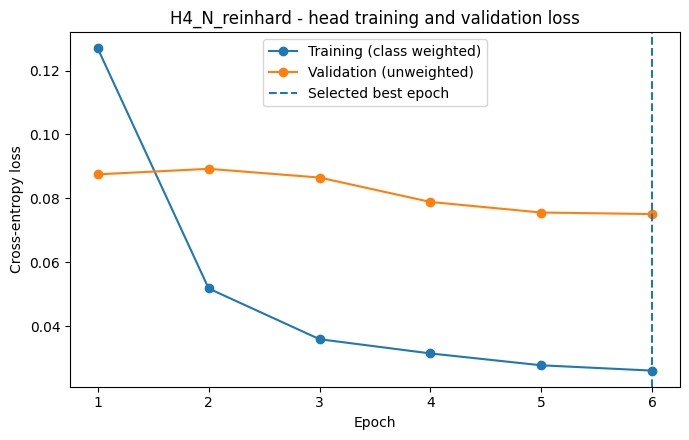

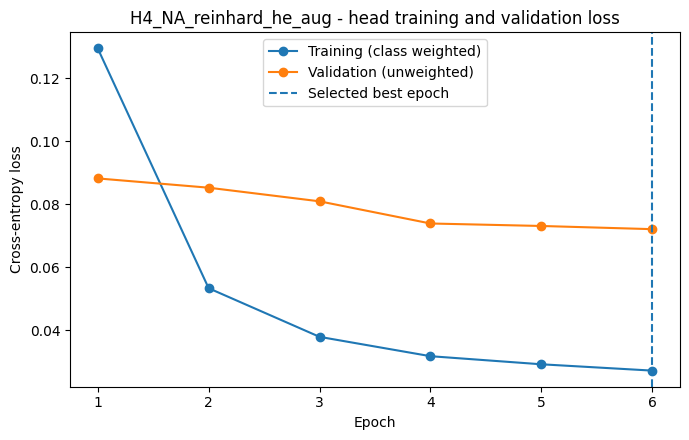

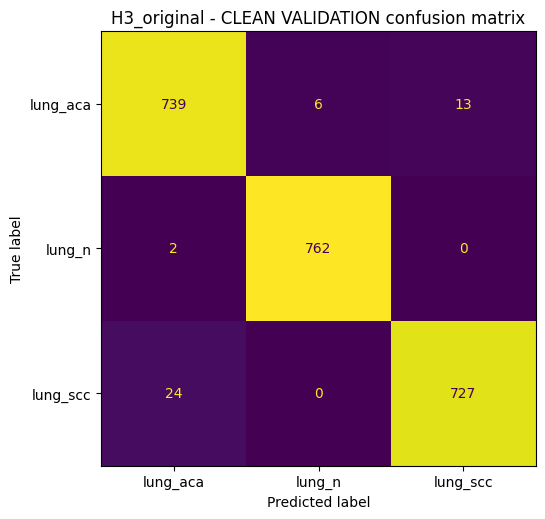

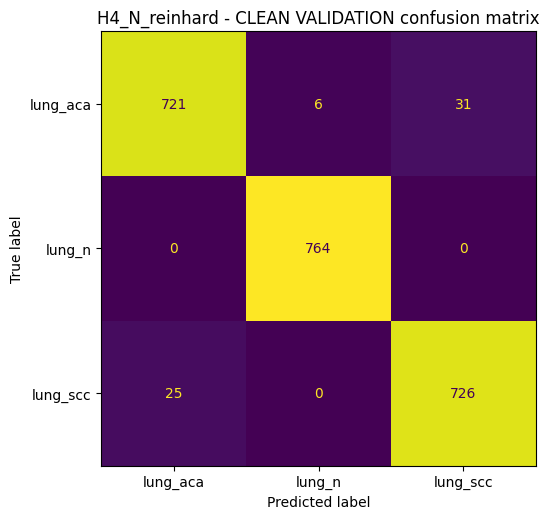

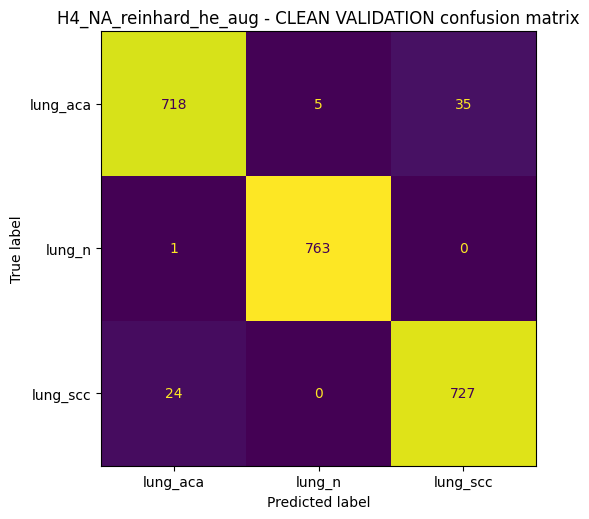

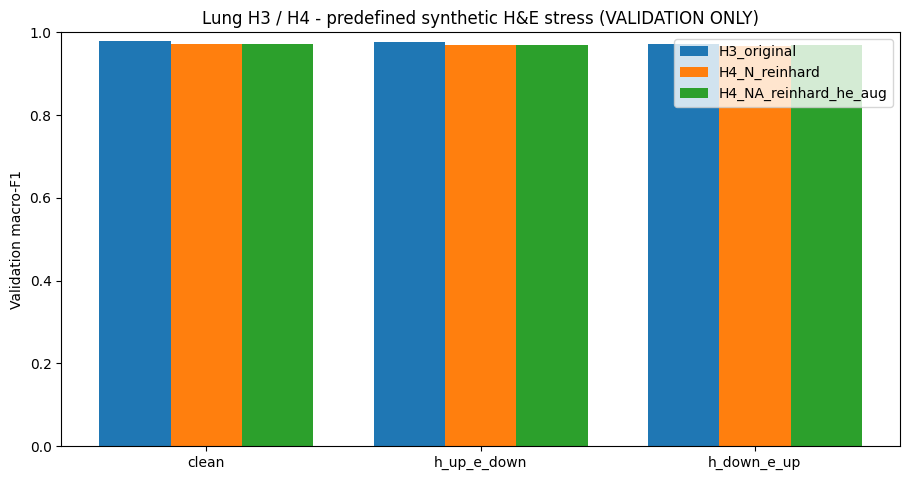

Full H4 experimental comparison; not held-out testing:


shift,clean,h_down_e_up,h_up_e_down,shift_mean_macro_f1,worst_shift_macro_f1,mean_drop_from_clean
condition,,,,,,
H3_original,0.980139,0.971283,0.976148,0.973715,0.971283,0.006423
H4_NA_reinhard_he_aug,0.971261,0.969954,0.970407,0.970180,0.969954,0.001081
H4_N_reinhard,0.972577,0.968144,0.969955,0.969050,0.968144,0.003527


Saved new H4 evidence: /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42/H4_Reinhard_HE_Aug_Robustness_seed42_evidence.zip
Saved H4 full results: /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H4_Reinhard_HE_Aug_Robustness_seed42
All synthetic-robustness and clean results: VALIDATION ONLY.
Held-out test: NOT evaluated.
H4 experiment notebook complete for this run mode.


In [15]:
# Final H4-only artifacts. All model choices remain validation-based until explicitly frozen.
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import zipfile

if MODE == 'evaluate_saved':
    print('Read-only mode: existing figures and reports are preserved, not overwritten.')
    display(ROBUSTNESS_TABLE.round(5))
    print('Previously saved H4 result directory:', RUN_DIR)
else:
    status = read_json(RUN_DIR/'training_status.json')
    if status.get('state') != 'validated_not_exported':
        raise RuntimeError('H4 validation step must finish before new result export.')
    if sha256_file(H4_CACHE_METADATA) != CONFIG['feature_cache_metadata_sha256']:
        raise RuntimeError('H4 feature cache changed after model training.')
    if sha256_file(H3_DIR/'best_head.keras') != H3_HEAD_SHA256:
        raise RuntimeError('H3 original checkpoint changed during H4.')
    if sha256_file(SOURCE_FILES['manifest']) != EXPECTED_MANIFEST_SHA256:
        raise RuntimeError('Original manifest changed during H4.')

    # Export inference graphs that accept externally NORMALIZED float32 RGB, not raw pixels.
    normalized_preview, _ = next(iter(make_image_dataset(val_df.head(BATCH_SIZE), 'norm')))
    preview_features = feature_model(normalized_preview, training=False).numpy()
    for condition in [H4_N,H4_NA]:
        head = new_heads[condition]
        expected_scores = head(preview_features, training=False).numpy()
        inp = keras.Input(shape=(*IMAGE_SIZE,3), dtype='float32',
                          name='externally_reinhard_normalized_rgb_0_255')
        output = head(feature_model(inp, training=False), training=False)
        normalized_input_model = keras.Model(
            inp, output, name='H4_Externally_Normalized_Input_' + condition)
        candidate = normalized_input_model(normalized_preview, training=False).numpy()
        np.testing.assert_allclose(candidate, expected_scores, rtol=4e-4, atol=4e-4)
        model_path = RUN_DIR/condition/'normalized_input_image_model.keras'
        normalized_input_model.save(model_path)
        restored = keras.models.load_model(model_path, compile=False)
        np.testing.assert_allclose(restored(normalized_preview, training=False).numpy(),
                                   expected_scores, rtol=4e-4, atol=4e-4)
        print('Saved normalized-input image model (needs external stain preprocessing):', model_path)
        del normalized_input_model, restored

    for condition in [H4_N,H4_NA]:
        history = pd.read_csv(RUN_DIR/condition/'training_history.csv')
        if history.empty:
            raise ValueError('Missing training history for ' + condition)
        best_epoch = status['conditions'][condition]['best_epoch']
        fig, ax = plt.subplots(figsize=(7,4.5))
        epochs = history['epoch'].to_numpy(dtype=int) + 1
        ax.plot(epochs, history['loss'], marker='o', label='Training (class weighted)')
        ax.plot(epochs, history['val_loss'], marker='o', label='Validation (unweighted)')
        ax.axvline(best_epoch, linestyle='--', label='Selected best epoch')
        ax.set(xlabel='Epoch', ylabel='Cross-entropy loss',
               title=f'{condition} - head training and validation loss')
        ax.legend()
        fig.tight_layout()
        fig.savefig(RUN_DIR/condition/'training_loss.png',dpi=180,bbox_inches='tight')
        plt.show()
        plt.close(fig)

    # Confusion matrices on original clean validation inputs, one per condition.
    for condition in ['H3_original', H4_N, H4_NA]:
        key = condition + '__clean'
        cm = np.asarray(validation_details[key]['confusion_matrix'],dtype=int)
        fig, ax = plt.subplots(figsize=(6.8,5.3))
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
            ax=ax, values_format='d', colorbar=False)
        ax.set_title(f'{condition} - CLEAN VALIDATION confusion matrix')
        fig.tight_layout()
        fig.savefig(RUN_DIR/(key + '_confusion_matrix.png'),dpi=180,bbox_inches='tight')
        plt.show()
        plt.close(fig)

    # Synthetic stress performance is not real-institution robustness evidence.
    fig, ax = plt.subplots(figsize=(9.2,4.9))
    positions = np.arange(len(VALIDATION_SHIFTS))
    plot_shifts = list(VALIDATION_SHIFTS)
    width = 0.26
    for offset, condition in enumerate(['H3_original',H4_N,H4_NA]):
        vals = [validation_details[condition+'__'+shift]['validation_macro_f1']
                for shift in plot_shifts]
        ax.bar(positions + (offset-1)*width, vals, width=width, label=condition)
    ax.set_xticks(positions, labels=plot_shifts)
    ax.set(ylabel='Validation macro-F1', ylim=(0,1),
           title='Lung H3 / H4 - predefined synthetic H&E stress (VALIDATION ONLY)')
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR/'validation_synthetic_shift_macro_f1.png',dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)

    selection_table = ROBUSTNESS_TABLE.copy().round(6)
    print('Full H4 experimental comparison; not held-out testing:')
    display(selection_table)
    baseline_clean = float(selection_table.loc['H3_original','clean'])
    n_clean = float(selection_table.loc[H4_N,'clean'])
    na_clean = float(selection_table.loc[H4_NA,'clean'])
    summary = f"""# Lung H4: Reinhard stain normalization and H&E-inspired augmentation

## Method and source data

Fixed LC25000 lung-only manifest SHA-256: `{EXPECTED_MANIFEST_SHA256}`. Frozen saved
H1 MobileNetV2 and H2 EfficientNetB0 pre-dropout pooled features (1,280 each) were
concatenated into 2,560-dimensional features, followed by two separately trained
Dropout(0.2) -> Dense(3,softmax) heads. Original H3 remained unchanged as control.

Train: {len(train_df):,} images ({EXPECTED_GROUPS['train']} reconstructed source-image groups);
validation: {len(val_df):,} images ({EXPECTED_GROUPS['val']} reconstructed groups);
held-out test: {EXPECTED_IMAGES['test']:,} images (not accessed or evaluated).
Reconstructed source groups are NOT independent patients, slides or hospitals.

Train-reference Reinhard normalization used {len(ref_df)} original training images
({REFERENCE_PER_CLASS} per class), pooled masked LAB mean/std, and a bounded LAB
standard-deviation rescaling. Every H4-NA training image received one deterministic
offline training view, with H&E-inspired OD concentration factors; approximately
{100*AUGMENT_PROBABILITY:.0f}% of rows were modified. This is NOT epochwise augmentation.
H4-N and H4-NA used identical numbers of training rows and identical normalized
validation features. H&E synthetic stress shifts were predeclared and applied before
normalization at inference (except H3, which uses its original raw pipeline).

## Validation results (not held-out test)

Clean validation macro-F1: H3 {baseline_clean:.6f}, H4-N {n_clean:.6f},
H4-NA {na_clean:.6f}. See `validation_condition_metrics.csv`,
`validation_robustness_summary.csv` and `validation_details.json` for
per-shift classification results, accuracy, class-wise metrics and confusion matrices.
Values are descriptive; the clean/shifted data are images of the SAME validation
source groups, not independent new hospital cases. The use of validation data for
checkpoint selection and model comparison may induce selection optimism.

## Limits and reproducibility

The two predefined perturbations are synthetic, not real stain/scanner/hospital
shift. Reinhard color statistics do not explicitly deconvolve stains. The chosen
H&E basis is fixed and inspired by conventional H&E optical-density vectors;
its concentration scaling and the resulting transformed images are approximations.
Results do not demonstrate patient-level, hospital-level, clinical, or external
stain robustness. Any raw-image H4 inference must reproduce this notebook's
resize-with-pad, training-only target reference statistics, transform order,
and H1/H2 backbone preprocessing; the exported H4 image-input Keras graphs
accept *already normalized* RGB and DO NOT include Reinhard normalization.

H1, H2 and H3 checkpoints remain unchanged. No held-out test images were read
or evaluated in H4. Final test evaluation must be separate and performed only
after validation-based pipeline selection is frozen.
"""
    (RUN_DIR/'RUN_SUMMARY.md').write_text(summary,encoding='utf-8')
    status['state'] = 'exported_validation_only'
    status['completed_utc'] = datetime.now(timezone.utc).isoformat()
    status['held_out_test_evaluated'] = False
    save_json(RUN_DIR/'training_status.json',status)

    file_digests = {}
    for path in sorted(RUN_DIR.rglob('*')):
        if path.is_file() and path.name not in {'artifact_checksums.json'} and not path.name.endswith('_evidence.zip'):
            file_digests[str(path.relative_to(RUN_DIR))] = sha256_file(path)
    save_json(RUN_DIR/'artifact_checksums.json', file_digests)

    # Portable small evidence only: no image pixels, large feature arrays or full image models.
    zipped = RUN_NAME + '_evidence.zip'
    excluded = {'normalized_input_image_model.keras'}
    evidence_path = Path('/content')/zipped
    with zipfile.ZipFile(evidence_path,'w',compression=zipfile.ZIP_DEFLATED,
                         compresslevel=5) as archive:
        for path in sorted(RUN_DIR.rglob('*')):
            if path.is_file() and path.name not in excluded and path.name != zipped:
                archive.write(path, str(path.relative_to(RUN_DIR)))
    destination = RUN_DIR/zipped
    shutil.copy2(evidence_path, destination)
    if sha256_file(evidence_path) != sha256_file(destination):
        raise IOError('Portable evidence ZIP copy did not verify.')
    print('Saved new H4 evidence:', destination)
    print('Saved H4 full results:', RUN_DIR)
    print('All synthetic-robustness and clean results: VALIDATION ONLY.')
    print('Held-out test: NOT evaluated.')

print('H4 experiment notebook complete for this run mode.')


## Reproducing a completed H4 run

Save an executed notebook copy after Section 13, including the actual outputs. Do **not** rerun H1, H2 or H3. To inspect an H4 run later, set Section 3 `MODE = 'evaluate_saved'` **before executing anything after mounting**, run the numbered sections sequentially to validate original sources, use the verified H4 feature cache, and load saved H4 heads. Sections 10/11 skip fitting; Section 12 recomputes validation-only comparisons in memory; Section 13 is read-only. In any mode, neither test images nor test performance are used here.

If a new run was interrupted during feature extraction or fitting, do **not** simply delete `.building` folders or partial checkpoints and rerun. Preserve artifacts and investigate the stage and saved training status before deciding on a reproducible recovery plan.

## Method and evidence notes

- The source H1/H2/H3 methods, model-internal preprocessing and exact source-group split were checked against the uploaded `H1_Lung_MobileNetV2_Baseline.ipynb`, `H2_Lung_EfficientNetB0_Baseline.ipynb`, and `H3_Lung_Deep_Feature_Fusion.ipynb`, plus `PROJECT_HANDOFF_2026-10-19_POST_H3.md`.
- LC25000 original lung-only split manifest, reconstructed source-image groups and SHA-256 evidence are authoritative. The split is not independent by patient, slide, or laboratory.
- Reinhard normalization here is a **custom bounded fixed-reference LAB-statistics implementation**, not a licensed clinical-grade stain harmonization method. The H&E optical-density perturbation uses **fixed canonical stain basis vectors with residual-preserving scaling**, not data-fitted physical stain-concentration measurements; visual QA is essential.
- Main reported outputs are accuracy, macro-F1, class precision/recall/F1, and confusion matrices **on validation** under unchanged and two predetermined synthetic color shifts. A drop in macro-F1 is defined as clean minus shifted macro-F1 (positive is worse under shift).
- There is no augmentation-only (without normalization) condition; the H4-N vs H4-NA comparison isolates only the additional effect of augmentation **under Reinhard normalization**. Neither synthetic robustness nor Grad-CAM can establish clinical correctness. No new test-set result is generated here. The two reports remain a separate deliverable due 21-22 October 2026.
